# PTB-XL ECG — Supervised Mamba Evaluation

**Notebook 06 / Research Pipeline: PTB-XL Self-Supervised ECG Representation Learning**

Author: Medical AI Research Team &nbsp;|&nbsp; Platform: Kaggle (Tesla T4, 16GB) &nbsp;|&nbsp; Framework: PyTorch 2.x

---

This notebook performs a **complete, held-out evaluation** of the supervised Mamba classifier
trained in **Notebook 05 — Supervised Mamba Training**. It loads the frozen `best_mamba.pth`
checkpoint and the official PTB-XL **test fold (fold 10)** — produced, unmodified, by
**Notebook 02 — Preprocessing & Reusable Data Pipeline** — and reports every metric, curve,
representation-space visualization, explainability artifact, and error-analysis breakdown needed
to characterize the model's behavior before it is compared against anything else.

**Scope of this notebook — evaluation only.** No parameter of `best_mamba.pth` is updated anywhere
below. Self-supervised pretraining, cross-architecture model comparison, ablation studies, and
hyperparameter search are all explicitly out of scope and deferred to later notebooks.



## Section 1 — Introduction

### 1.1 Purpose
Notebook 05 optimized `MambaClassifier` against the **validation** fold (fold 9) for early
stopping and model selection. Validation performance is therefore an optimistic, indirectly-fit
signal — it influenced which checkpoint was kept. The **test fold (fold 10)** was never touched by
training, augmentation-search, or early-stopping decisions in Notebook 05, so it is the only split
that can produce an unbiased estimate of real-world generalization. This notebook exists to compute
that estimate, rigorously and reproducibly, exactly once.

### 1.2 Why evaluation deserves its own notebook
A single scalar (macro-AUROC) cannot answer "is this model trustworthy for a given diagnostic
superclass, and where does it fail?" Multi-label clinical classification has heterogeneous class
prevalence (NORM is common, HYP is comparatively rare), heterogeneous clinical cost of errors (a
missed MI is worse than a missed NORM), and a decision boundary (0.5) that is a convention, not a
law. Full evaluation — per-class metrics, calibration, representation geometry, explainability, and
explicit error inspection — is what turns a checkpoint into a characterized model.

### 1.3 Overview of this notebook
1. **Environment & artifacts** — load `best_mamba.pth`, `training_history.csv`, `config.json`.
2. **Test data** — the untouched fold-10 loader from Notebook 02, reused verbatim.
3. **Model reconstruction** — rebuild `MambaClassifier` identically from the frozen config and
   load the trained weights in `eval()` mode.
4. **Inference** — a single forward pass over the test set, producing probabilities, thresholded
   labels, ground truth, and per-sample confidence.
5. **Metrics, curves, representation analysis, explainability, and error analysis** — the full
   battery specified for this notebook.
6. **Computational profile** — parameter count, model size, latency, throughput, memory, FLOPs.
7. **Export** — every artifact persisted to disk for the future SSL-vs-supervised comparison in
   Notebooks 07–08.

## Section 2 — Environment Setup

Installs the same `mamba_ssm` / `causal-conv1d` kernels used in Notebook 05 (required to
reconstruct the architecture), plus `captum` (explainability), `umap-learn` (representation
analysis), and `thop` (FLOP estimation) — all idempotent, skipped if already present. Then
verifies GPU/CUDA/PyTorch and fixes every RNG.

In [1]:
# Section 2.1 — Install Required Packages
# ---------------------------------------------------------------------------
# NOTE: idempotent — safe to re-run. mamba_ssm/causal-conv1d must match Notebook 05's
# install exactly so the reconstructed architecture loads the checkpoint without error.

import importlib
import subprocess
import sys


def ensure_package(pkg_import_name: str, pip_spec: str, extra_args=None) -> bool:
    """Install a package via pip only if it is not already importable.

    Parameters
    ----------
    pkg_import_name : str
        Name used in `import <pkg_import_name>`.
    pip_spec : str
        Argument passed to `pip install` (name, extras, or version pin).
    extra_args : list[str], optional
        Additional flags forwarded to `pip install`.

    Returns
    -------
    bool
        True if the package is importable after this call.
    """
    try:
        importlib.import_module(pkg_import_name)
        print(f"[OK] {pkg_import_name} already available.")
        return True
    except ImportError:
        print(f"[INSTALL] {pip_spec} not found — installing...")
        cmd = [sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation", pip_spec]
        cmd[-1:-1] = extra_args or []
        result = subprocess.run(cmd, capture_output=True, text=True)
        ok = result.returncode == 0
        if not ok:
            print(f"[WARN] pip install failed for {pip_spec}:\n{result.stderr[-1500:]}")
        return ok


_causal_conv1d_ok = ensure_package("causal_conv1d", "causal-conv1d>=1.4.0")
_mamba_ssm_ok = ensure_package("mamba_ssm", "mamba-ssm")
if not _mamba_ssm_ok:
    raise RuntimeError(
        "mamba_ssm failed to install. On Kaggle, prefer attaching a prebuilt-wheel dataset "
        "matching this kernel's torch/CUDA version, as in Notebook 05."
    )

_captum_ok = ensure_package("captum", "captum")
_umap_ok = ensure_package("umap", "umap-learn")
_thop_ok = ensure_package("thop", "thop")

from mamba_ssm import Mamba

[INSTALL] causal-conv1d>=1.4.0 not found — installing...
[INSTALL] mamba-ssm not found — installing...
[INSTALL] captum not found — installing...
[OK] umap already available.
[INSTALL] thop not found — installing...


In [2]:
# Section 2.2 — Core Imports
# ---------------------------------------------------------------------------

import glob
import json
import os
import random
import time
import warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.patches import Patch

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score, balanced_accuracy_score,
    hamming_loss, accuracy_score, multilabel_confusion_matrix, confusion_matrix,
    classification_report,
)

import umap
from captum.attr import IntegratedGradients, Saliency

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
    print(f"Compute capable : {torch.cuda.get_device_capability(0)}")
    print(f"VRAM total      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4
Compute capable : (7, 5)
VRAM total      : 15.6 GB


In [3]:
# Section 2.3 — Reproducibility
# ---------------------------------------------------------------------------

def set_global_seed(seed: int, deterministic: bool = True) -> None:
    """Seed every RNG used in this notebook for reproducible evaluation.

    Parameters
    ----------
    seed : int
        Seed value applied to Python's `random`, NumPy, and PyTorch (CPU + CUDA).
    deterministic : bool
        If True, force cuDNN into deterministic mode, matching the convention set in
        Notebooks 02 and 05 so t-SNE/UMAP initializations and dropout-free inference
        are bit-reproducible across reruns.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.benchmark = True
    os.environ["PYTHONHASHSEED"] = str(seed)


_SEED = 42  # re-synced against the frozen training CONFIG once located in Section 2.4
set_global_seed(_SEED)
print(f"Global seed set to {_SEED}.")

Global seed set to 42.


### 2.4 Locate trained artifacts

Searches `/kaggle/input` (attached Notebook-05 output dataset) and common local paths for
`best_mamba.pth`, `training_history.csv`, and `config.json` — the three artifacts Notebook 05
persisted via its `CheckpointManager`. `config.json` is the frozen record of the exact
architecture hyperparameters used at training time, so Section 4 rebuilds the model from *that*
file rather than from possibly-drifted defaults, guaranteeing an identical reconstruction.

In [4]:
# Section 2.4 — Locate Trained Artifacts
# ---------------------------------------------------------------------------

def locate_checkpoint_dir(required_files=("best_mamba.pth", "training_history.csv", "config.json"),
                           search_roots=("/kaggle/input", "./mamba_supervised_outputs/checkpoints",
                                         "/mnt/user-data/uploads", ".", "..")) -> str:
    """Find the directory containing Notebook 05's saved checkpoint artifacts.

    Parameters
    ----------
    required_files : tuple[str, ...]
        Filenames that must all be present in a candidate directory.
    search_roots : tuple[str, ...]
        Roots to search recursively, in priority order.

    Returns
    -------
    str
        Path to the directory containing all `required_files`.

    Raises
    ------
    FileNotFoundError
        If no directory under any search root contains every required file.
    """
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        hits = glob.glob(os.path.join(root, "**", "best_mamba.pth"), recursive=True)
        for hit in hits:
            candidate_dir = os.path.dirname(hit)
            if all(os.path.exists(os.path.join(candidate_dir, f)) for f in required_files):
                return candidate_dir
    raise FileNotFoundError(
        "Could not locate best_mamba.pth / training_history.csv / config.json. On Kaggle, "
        "attach Notebook 05's output as a data source (Add Data -> Notebooks -> "
        "05-supervised-mamba-training) so its checkpoints directory appears under /kaggle/input."
    )


CHECKPOINT_DIR = locate_checkpoint_dir()
with open(os.path.join(CHECKPOINT_DIR, "config.json")) as f:
    TRAINED_CONFIG = json.load(f)

print(f"Checkpoint directory located : {CHECKPOINT_DIR}")
print("\nFrozen training configuration (config.json):")
for k, v in TRAINED_CONFIG.items():
    print(f"  {k:28s}: {v}")

Checkpoint directory located : /kaggle/input/notebooks/shamsuzzamanhisham/ptb-xl-ecg-supervised-mamba-trainin-v2-improved/mamba_supervised_v2_outputs/checkpoints

Frozen training configuration (config.json):
  LEARNING_RATE               : 0.0003
  WEIGHT_DECAY                : 0.0003
  BATCH_SIZE                  : 64
  EPOCHS                      : 50
  WARMUP_EPOCHS               : 3
  DROPOUT                     : 0.35
  LABEL_SMOOTHING             : 0.05
  USE_POS_WEIGHT              : True
  POS_WEIGHT_MAX              : 8.0
  EMBED_DIM                   : 128
  HIDDEN_DIM                  : 256
  N_MAMBA_LAYERS              : 6
  D_STATE                     : 16
  D_CONV                      : 4
  EXPAND                      : 2
  BIDIRECTIONAL               : True
  POOLING                     : mean_attention
  SCHEDULER_TYPE              : warmup_cosine
  MIN_LR                      : 1e-06
  GRAD_CLIP_NORM              : 1.0
  MIXED_PRECISION             : True
  EARLY_STOPP

### 2.5 Evaluation configuration

`EVAL_CONFIG` centralizes every path and hyperparameter specific to *this* notebook (batch size
for inference, decision threshold, output directories, sample caps for the more expensive
analyses). It stays a separate object from `TRAIN_CONFIG`/`CONFIG` for the same reason Notebook 05
kept its own config: reusing upstream notebooks verbatim must never silently mutate their state.

In [5]:
# Section 2.5 — Evaluation Configuration
# ---------------------------------------------------------------------------

class EVAL_CONFIG:
    """Central configuration for supervised Mamba evaluation (Notebook 06 only).

    Signal/data constants (`SIGNAL_LENGTH`, `N_LEADS`, `N_CLASSES`, ...) live in `CONFIG`
    (Notebook 02, loaded in Section 3) and architecture constants are read from the frozen
    `TRAINED_CONFIG` (Section 2.4) — neither is duplicated here.
    """

    # ---- Inference --------------------------------------------------------------------
    BATCH_SIZE: int = 128          # larger than training batch size; no gradients held
    DECISION_THRESHOLD: float = 0.5   # fallback; per-class tuned thresholds loaded in Section 5.1 if available

    # ---- Representation analysis --------------------------------------------------------
    MAX_EMBEDDING_SAMPLES: int = 2500   # cap for t-SNE/UMAP (test fold ~2.2-2.5k records; no-op if smaller)
    TSNE_PERPLEXITY: float = 30.0
    UMAP_N_NEIGHBORS: int = 15
    UMAP_MIN_DIST: float = 0.1

    # ---- Explainability ------------------------------------------------------------------
    N_EXPLAIN_SAMPLES: int = 6          # representative ECGs per explainability figure
    IG_STEPS: int = 50                 # Integrated Gradients interpolation steps

    # ---- Error analysis --------------------------------------------------------------------
    N_ERROR_EXAMPLES: int = 4           # representative ECGs per error category
    HIGH_CONFIDENCE_THRESHOLD: float = 0.85
    LOW_CONFIDENCE_BAND: float = 0.10   # |p - 0.5| <= this counts as "low confidence"

    # ---- Computational profiling --------------------------------------------------------------
    N_LATENCY_RUNS: int = 50
    N_WARMUP_RUNS: int = 10
    LATENCY_BATCH_SIZE: int = 1         # single-sample latency (deployment-realistic)

    # ---- Reproducibility --------------------------------------------------------------------------
    RANDOM_SEED: int = 42               # re-synced against CONFIG.RANDOM_SEED once loaded in Section 3

    # ---- Output / figures / tables directories ---------------------------------------------------
    OUTPUT_DIR: str = "./mamba_evaluation_outputs"
    FIGURES_DIR: str = "./mamba_evaluation_outputs/figures"
    TABLES_DIR: str = "./mamba_evaluation_outputs/tables"
    PREDICTIONS_DIR: str = "./mamba_evaluation_outputs/predictions"
    EMBEDDINGS_DIR: str = "./mamba_evaluation_outputs/embeddings"
    EXPLAINABILITY_DIR: str = "./mamba_evaluation_outputs/explainability"
    EXPORTS_DIR: str = "./mamba_evaluation_outputs/exports"

    # ---- Device -------------------------------------------------------------------------------------
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


for _dir in [EVAL_CONFIG.OUTPUT_DIR, EVAL_CONFIG.FIGURES_DIR, EVAL_CONFIG.TABLES_DIR,
             EVAL_CONFIG.PREDICTIONS_DIR, EVAL_CONFIG.EMBEDDINGS_DIR,
             EVAL_CONFIG.EXPLAINABILITY_DIR, EVAL_CONFIG.EXPORTS_DIR]:
    os.makedirs(_dir, exist_ok=True)

print("EVAL_CONFIG initialized.")
print(f"Device            : {EVAL_CONFIG.DEVICE}")
print(f"Decision threshold: {EVAL_CONFIG.DECISION_THRESHOLD}")

EVAL_CONFIG initialized.
Device            : cuda
Decision threshold: 0.5


In [6]:
import subprocess
print(subprocess.run(["find", "/kaggle/input", "-iname", "*.ipynb"], capture_output=True, text=True).stdout)

/kaggle/input/notebooks/shamsuzzamanhisham/preprocessing-reusable-data-pipeline/__notebook__.ipynb
/kaggle/input/notebooks/shamsuzzamanhisham/ptb-xl-ecg-supervised-mamba-trainin-v2-improved/__notebook__.ipynb



## Section 3 — Load Test Dataset

Reuses **Notebook 02's** preprocessing pipeline exactly as written, identically to how Notebook 05
consumed it — no logic is reimplemented. Only the **test loader** (`get_test_loader()`, official
fold 10, no augmentation) is used from here on; the train/val loaders are never touched by this
notebook.

Loading Notebook 02 pipeline from: /kaggle/input/notebooks/shamsuzzamanhisham/preprocessing-reusable-data-pipeline/__notebook__.ipynb
[INSTALL] wfdb not found — installing quietly...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.5 MB/s eta 0:00:00
[OK] torch already available.
[OK] torchvision already available.
[OK] numpy already available.
[OK] pandas already available.
[OK] matplotlib already available.
[OK] plotly already available.
[OK] scipy already available.
[OK] sklearn already available.
[OK] torchmetrics already available.
[OK] tqdm already available.
PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4
CONFIG initialized.
Device: cuda
Target signal shape per record: (12, 1000)
PTB-XL dataset root detected at: /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
Global seed set to 42 (deterministic=True).
=== ptbxl_database.csv ===
Shape   : (21837, 27)
Columns : ['patie

,n_records
strat_fold,
1,2177
2,2184
3,2194
4,2175
5,2176
6,2178
7,2178
8,2179
9,2193



[PASS] Metadata shape / duplicate / fold-range checks.
Records with zero mapped diagnostic superclass: 407 (1.86%) — these will be excluded from supervised splits.

Multi-label binary matrix shape: (21837, 5)


,n_positive
NORM,9528
MI,5486
STTC,5250
CD,4907
HYP,2655



[PASS] Multi-label matrix row sums match n_labels for every record.

Saved -> ./ptbxl_preprocessing_outputs/processed/processed_labels.csv
ecg_id=   719  100Hz shape=(12, 1000)   500Hz shape=(12, 5000)
ecg_id= 20102  100Hz shape=(12, 1000)   500Hz shape=(12, 5000)
ecg_id=  9470  100Hz shape=(12, 1000)   500Hz shape=(12, 5000)


Validating signals:   0%|          | 0/3000 [00:00<?, ?it/s]


Valid signals: 3000 / 3000 (100.00%)

Failure counts by check (0 = no failures):


,n_failures
correct_dimensions,3000
correct_length,3000
correct_n_leads,3000
correct_fs,3000
corrupted_file,0
has_nan,0
has_inf,0
empty_signal,0
constant_signal,0


Computing signal statistics:   0%|          | 0/3000 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
min,3000.0,-1.666402,0.890543,-16.320000,-1.941000,-1.465000,-1.125000,-0.473000
max,3000.0,1.737413,0.787899,0.423000,1.221750,1.581000,2.061250,9.390000
mean,3000.0,-0.000656,0.007217,-0.208200,-0.001494,-0.000646,0.000205,0.286146
median,3000.0,-0.010461,0.016564,-0.236000,-0.020000,-0.011000,-0.003000,0.417000
variance,3000.0,0.051888,0.061023,0.005791,0.023747,0.035200,0.056038,0.743686
std,3000.0,0.209548,0.089336,0.076101,0.154100,0.187616,0.236724,0.862372
rms,3000.0,0.209597,0.089514,0.076110,0.154104,0.187622,0.236746,0.882744
energy,3000.0,623.290934,736.547218,69.512199,284.976913,422.425980,672.582489,9350.833984
skewness,3000.0,0.464645,2.269531,-15.100169,-0.933127,0.584169,1.965737,8.948092
kurtosis,3000.0,24.374119,18.816125,-0.656571,15.087336,21.863681,29.950029,571.509094


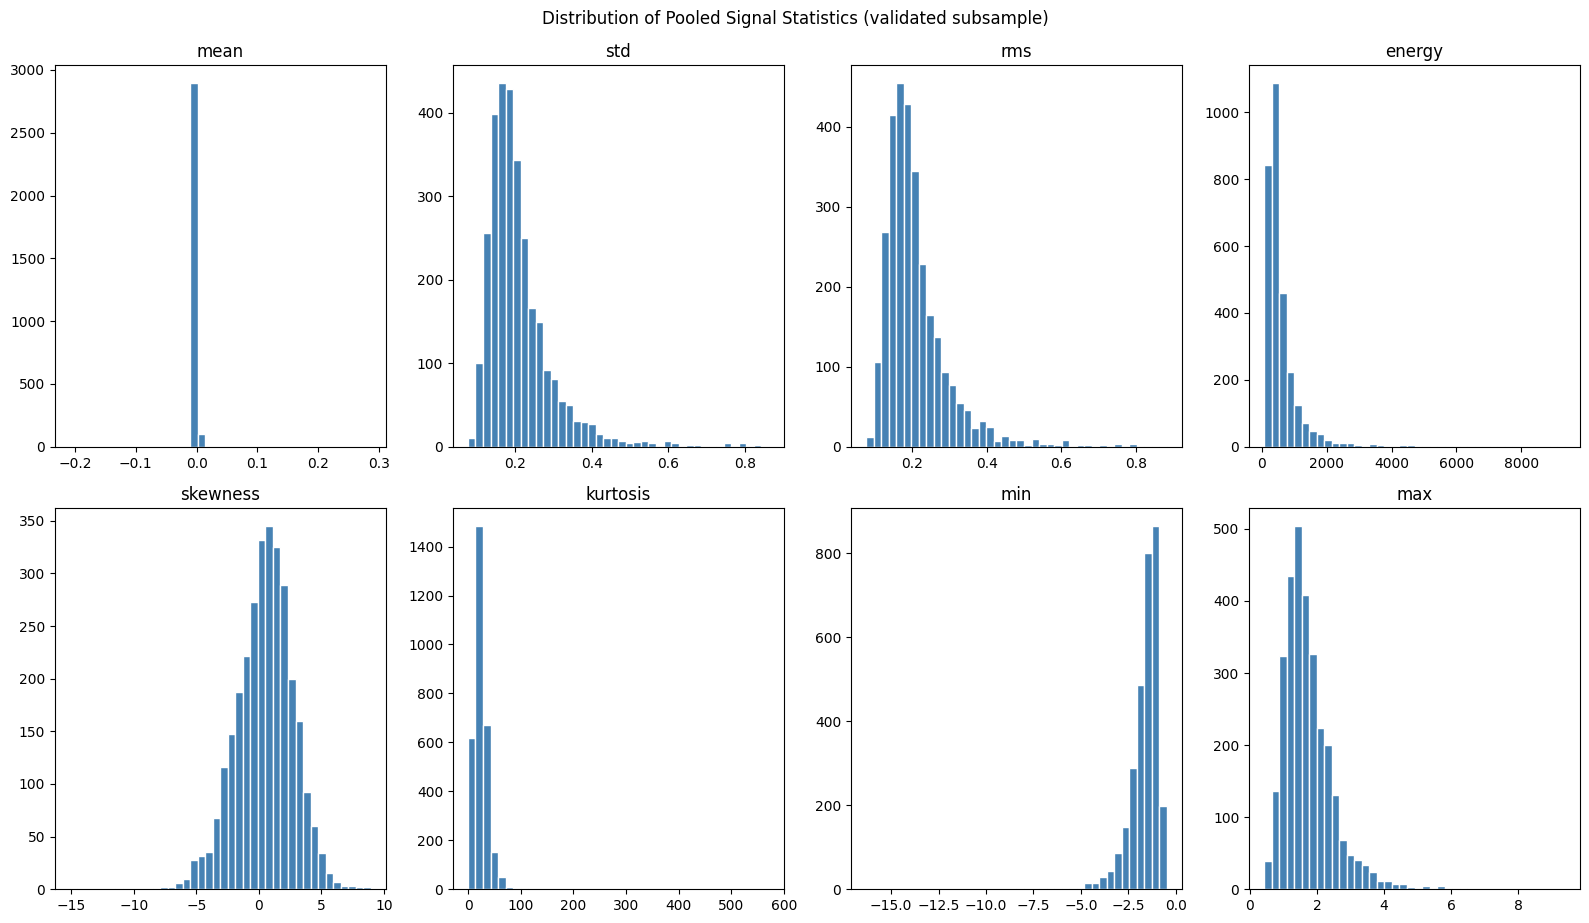

Fitted 'zscore' normalizer on 300 training-fold signals.


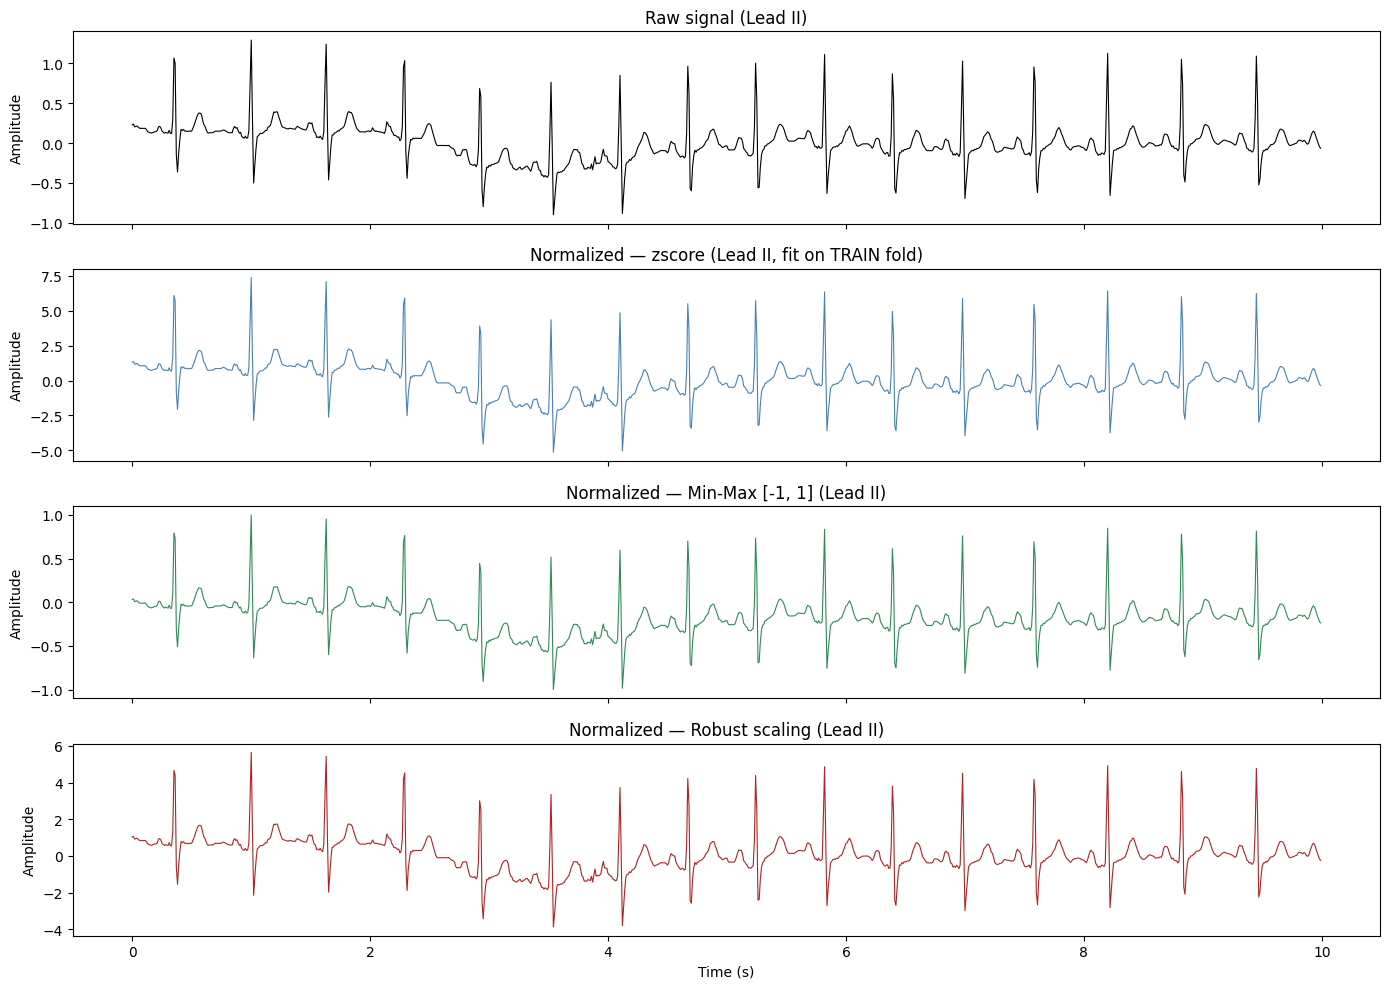

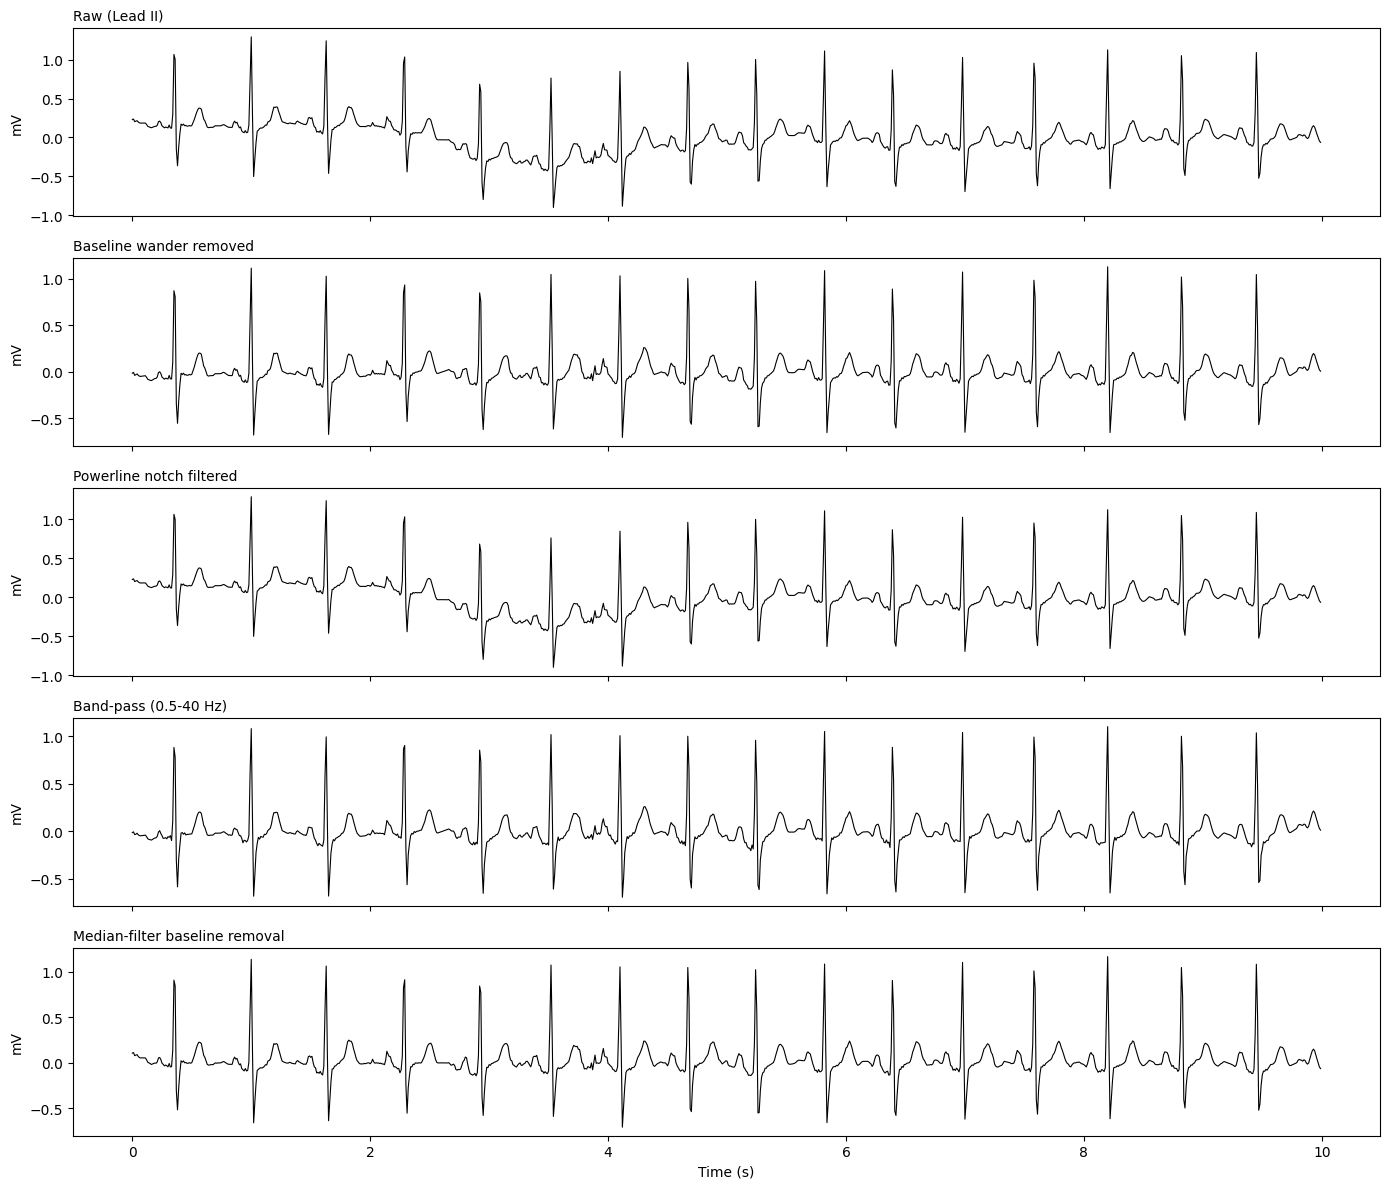

short input ( 800 samples) -> center: (12, 1000), random: (12, 1000)
exact input (1000 samples) -> center: (12, 1000), random: (12, 1000)
 long input (1300 samples) -> center: (12, 1000), random: (12, 1000)
ECGAugmentation initialized with ops: ['random_crop', 'time_stretch', 'random_time_shift', 'lead_dropout', 'random_masking', 'amplitude_scaling', 'random_scaling', 'gaussian_noise', 'random_jitter']


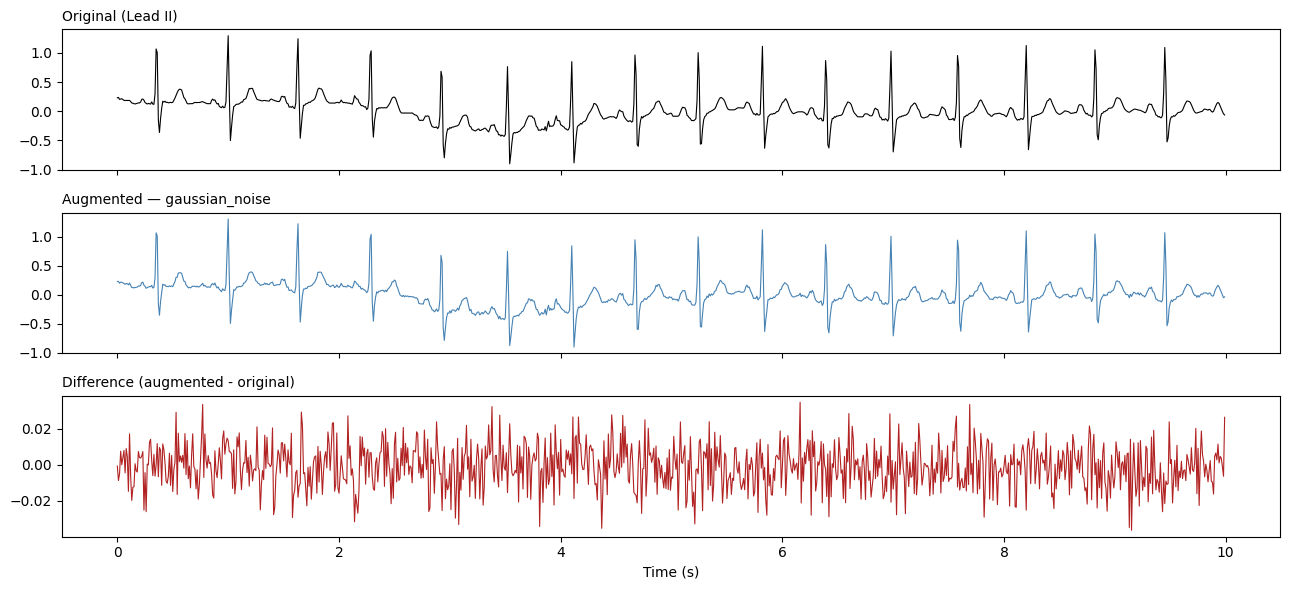

[gaussian_noise] Beneficial for robustness to electrode/EMG noise; excessive std can mask P/T waves.



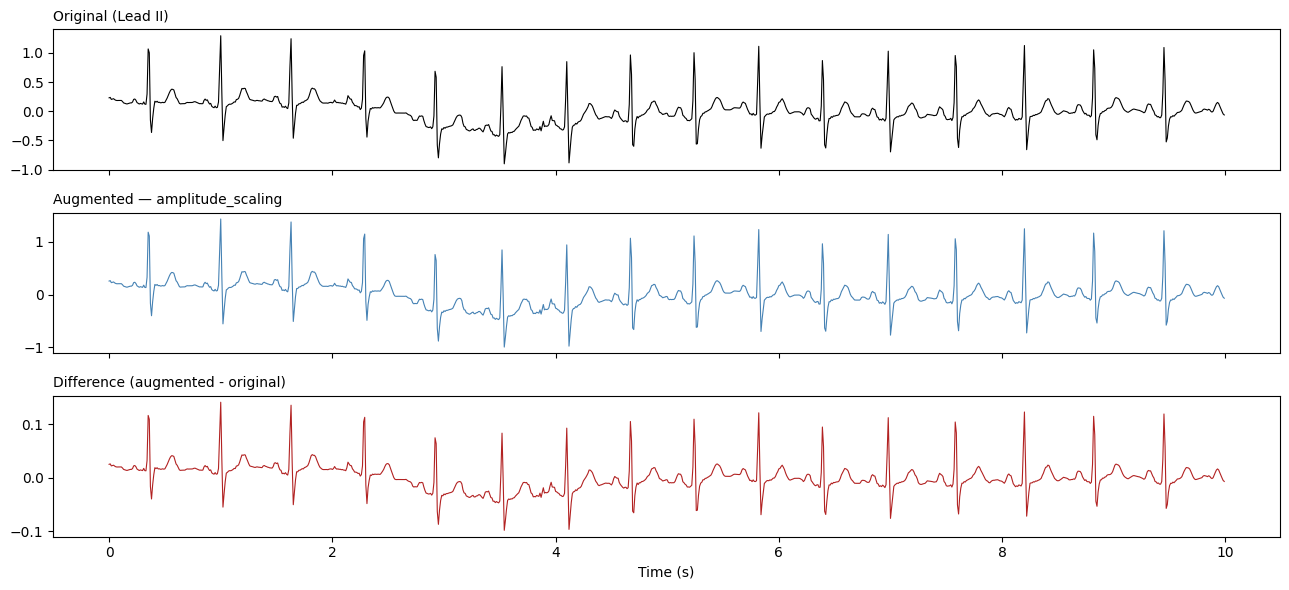

[amplitude_scaling] Beneficial for inter-patient/electrode-contact amplitude invariance.



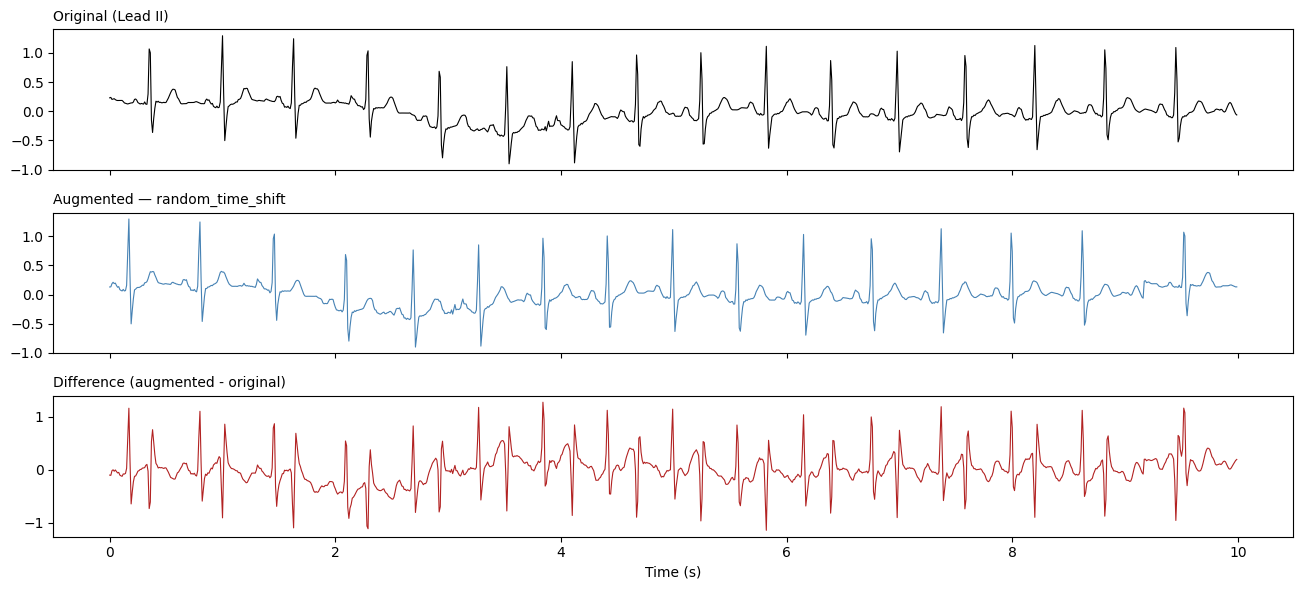

[random_time_shift] Beneficial for shift-invariant temporal features; keep shift small (<10%) to avoid clipping QRS out of frame.



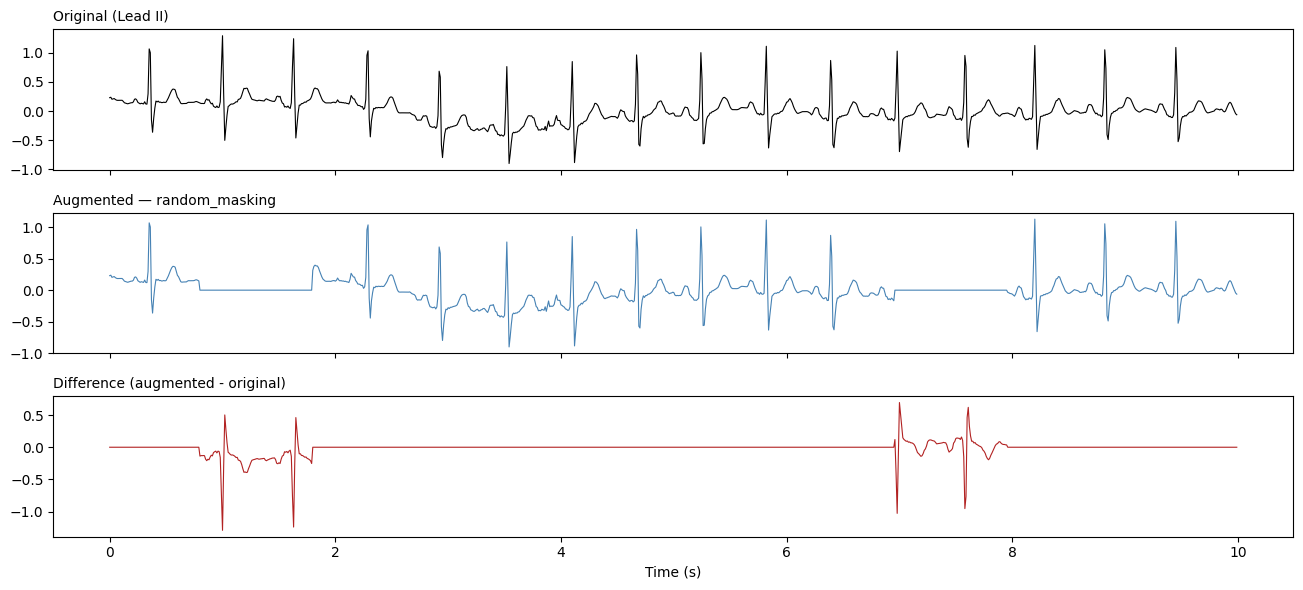

[random_masking] Beneficial as a lightweight cutout regularizer / SSL masked-reconstruction pretext signal.



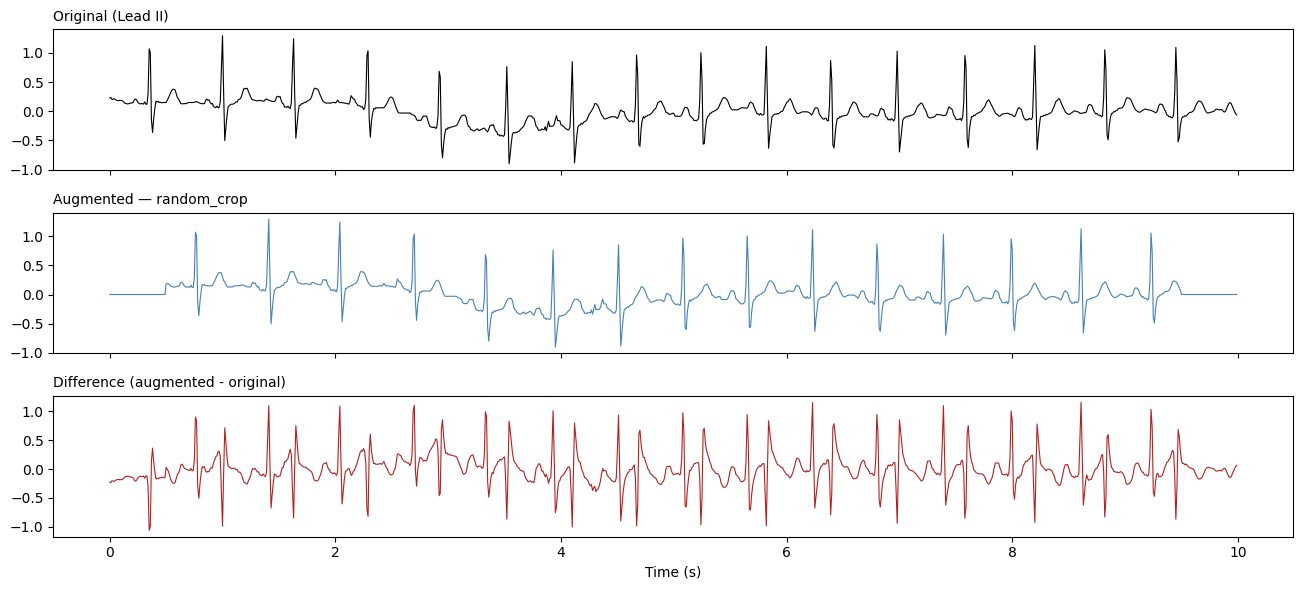

[random_crop] Beneficial for temporal-position invariance; avoid over-cropping which can remove full beats.



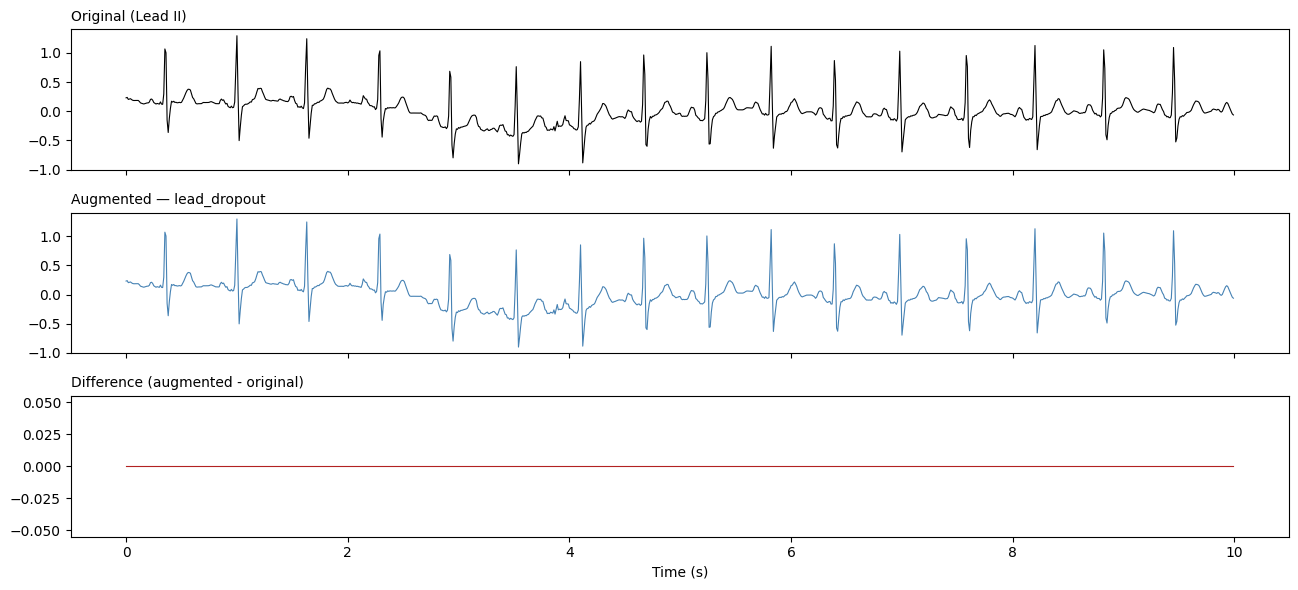

[lead_dropout] Beneficial for exploiting inter-lead redundancy (Einthoven/Goldberger); strong SSL pretext signal.



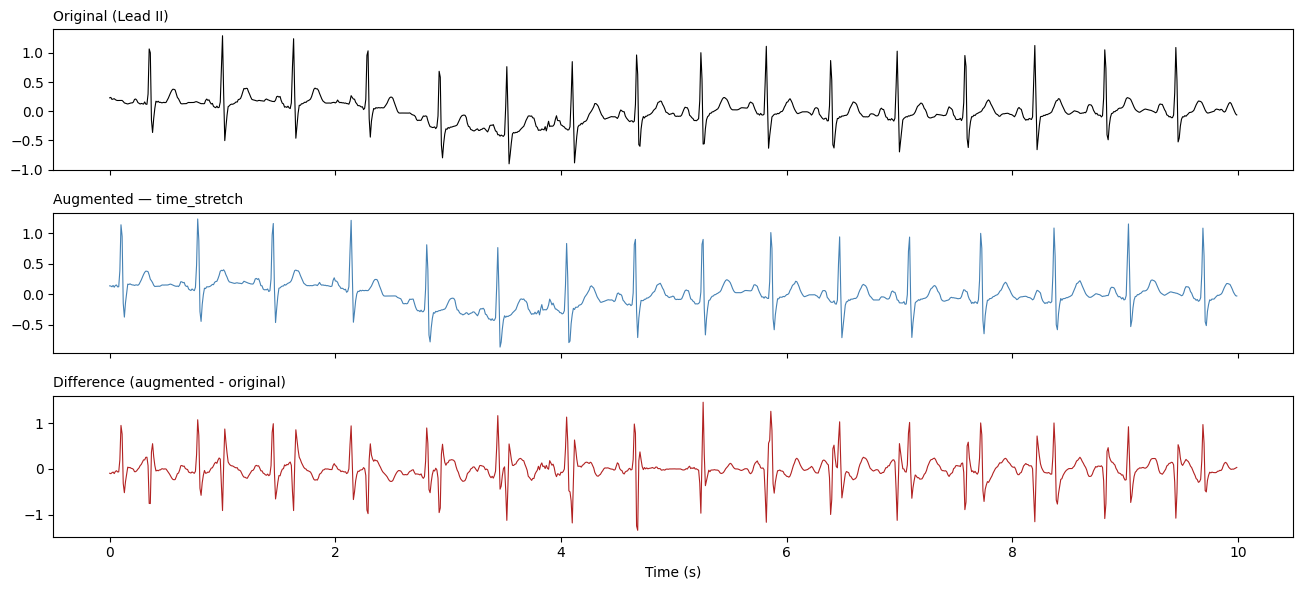

[time_stretch] Beneficial for heart-rate-variability robustness; extreme factors distort QRS morphology.



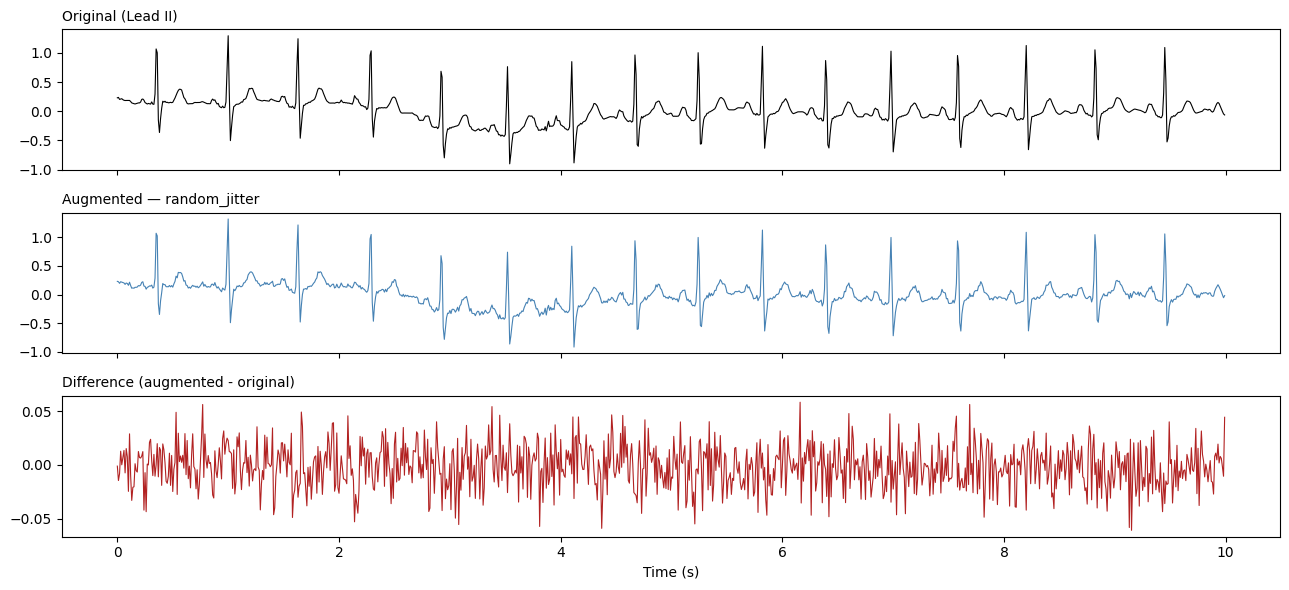

[random_jitter] Beneficial as a mild complement to gaussian_noise; small sigma keeps it a regularizer, not corruption.



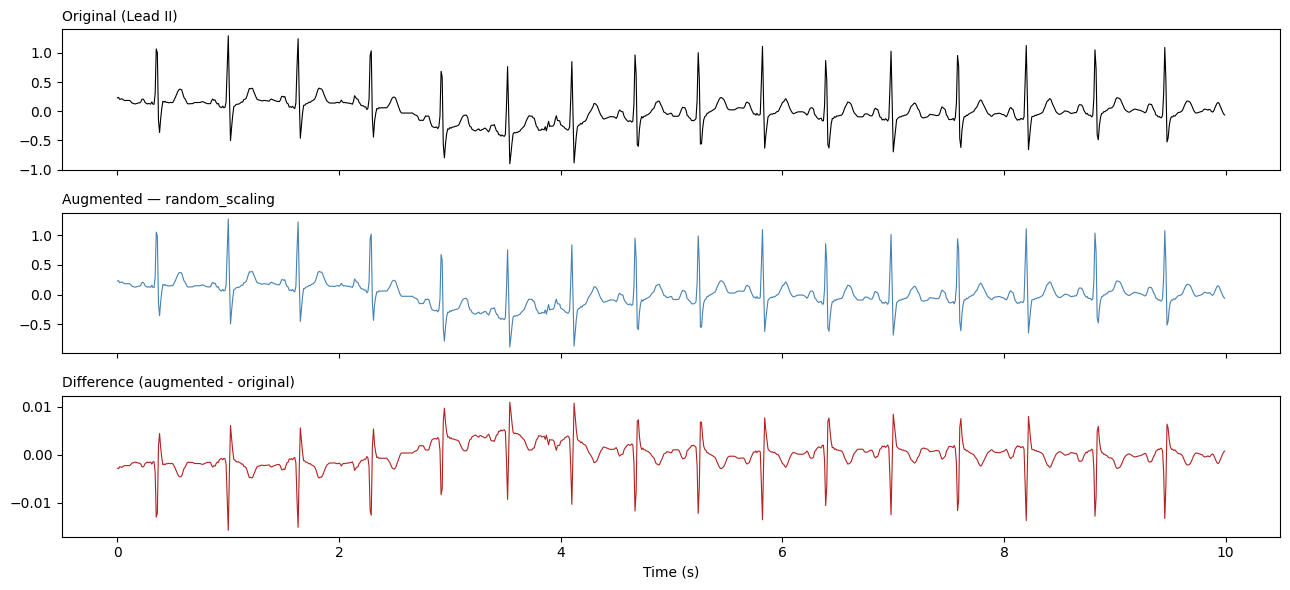

[random_scaling] Beneficial for per-lead gain-mismatch robustness (independent electrode calibration).

train:  17111 records
  val:   2156 records
 test:   2163 records

[PASS] No patient_id overlaps between train/val/test.

Per-split positive rate (%) by superclass:


,train,val,test
NORM,44.46,44.39,44.57
MI,25.65,25.23,25.57
STTC,24.50,24.77,24.18
CD,22.86,23.05,23.02
HYP,12.40,12.57,12.16



Max cross-split spread in positive rate: 0.59 pp (small values confirm the official stratification preserved class balance).
PTBXLDataset, PTBXLClassificationDataset, and PTBXLSSLDataset defined.
Sample 0 -> signal shape=(12, 1000), label shape=(5,), ecg_id=1
Smoke-test batch -> signals: (4, 12, 1000), labels: (4, 5)
Batch signals shape : (64, 12, 1000)   dtype=torch.float32
Batch labels  shape : (64, 5)    dtype=torch.float32
Example ecg_ids     : [14934, 11512, 13285, 12086, 763, 3388, 20276, 4862]
Example label rows  :
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [1. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]]


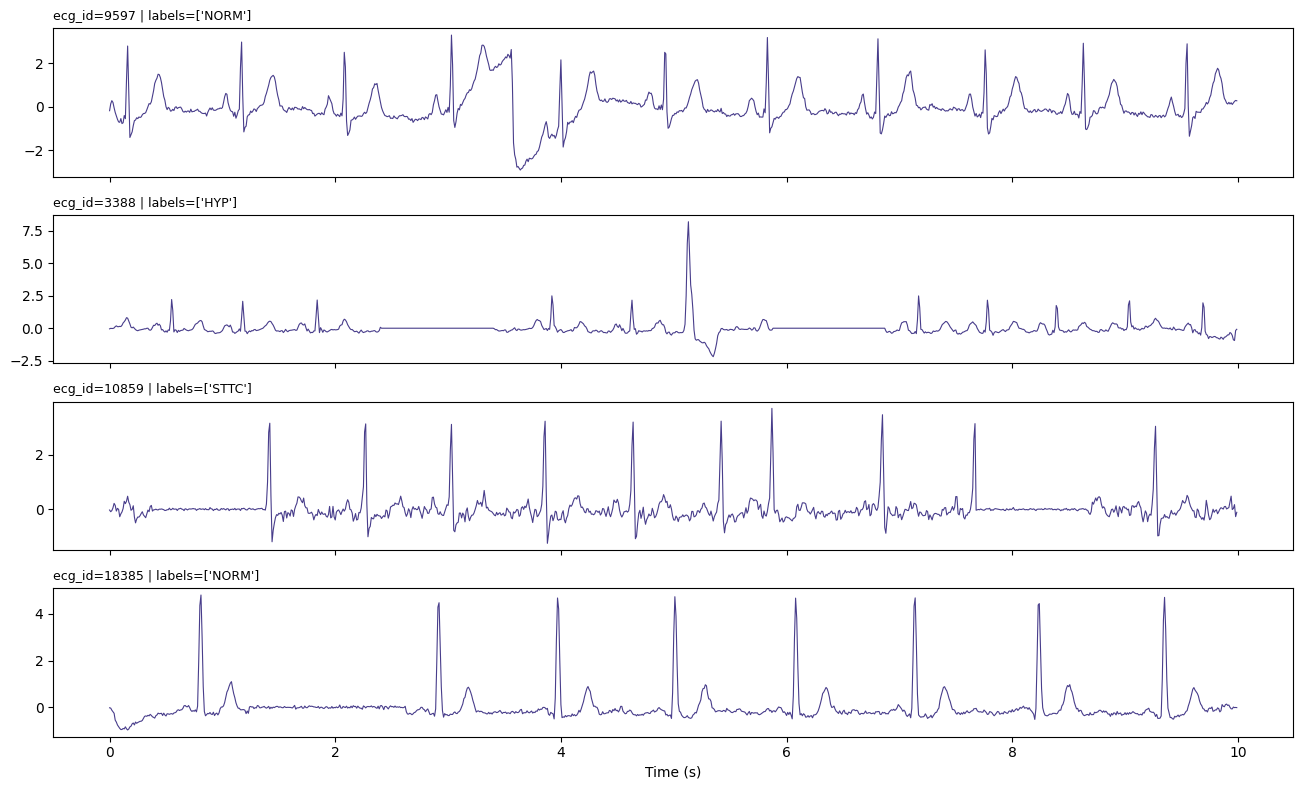

Dataset __getitem__ : 12.56 ms/item  (~79.6 items/sec, single process)
DataLoader batch    : 413.5 ms/batch  (~154.8 records/sec, num_workers=2)

CPU utilization (process): 0.0%
RAM usage (process)      : 2166.6 MB
System RAM usage         : 7.6%

GPU memory allocated : 0.0 MB
GPU memory reserved  : 0.0 MB
[NOTE] GPU utilization will be ~0% here since this notebook performs no forward/backward pass by design; measure it again in Notebook 03 once a model consumes these batches.


,check,passed
0,signal_shape_correct,True
1,label_shape_correct,True
2,no_patient_leakage,True
3,labels_are_binary,True
4,normalization_reasonable_scale,True
5,train_augmentation_is_stochastic,True
6,val_is_deterministic,True
7,no_nan_after_pipeline,True
8,no_inf_after_pipeline,True



[PASS] All quality-assurance checks passed.
Saved processed_metadata.csv     -> ./ptbxl_preprocessing_outputs/processed/processed_metadata.csv  (6723.7 KB)
Saved processed_labels.csv       -> ./ptbxl_preprocessing_outputs/processed/processed_labels.csv  (330.4 KB)
Saved dataset_statistics.csv     -> ./ptbxl_preprocessing_outputs/processed/dataset_statistics.csv  (0.2 KB)
Saved signal_statistics.csv      -> ./ptbxl_preprocessing_outputs/tables/signal_statistics.csv  (593.8 KB)
Saved quality_report.csv         -> ./ptbxl_preprocessing_outputs/tables/quality_report.csv  (183.2 KB)
Reusable API ready: get_train_loader, get_validation_loader, get_test_loader, get_ssl_loader, load_signal, normalize_signal, augment_signal.
train loader -> first tensor shape: (8, 12, 1000)
  val loader -> first tensor shape: (8, 12, 1000)
 test loader -> first tensor shape: (8, 12, 1000)
  ssl loader -> first tensor shape: (8, 12, 1000)

Notebook 02 executed into namespace: CONFIG, splits, label_matrix, get_t

In [7]:
# Section 3.1 — Locate and Execute Notebook 02 In-Namespace
# ---------------------------------------------------------------------------

import nbformat as _nbformat


def run_notebook_globals(notebook_path: str, target_globals: dict) -> None:
    """Execute every code cell of a notebook into `target_globals` (mirrors `%run` for .ipynb).

    Parameters
    ----------
    notebook_path : str
        Path to the `.ipynb` file to execute.
    target_globals : dict
        Namespace (typically `globals()`) that receives every name the notebook defines, so its
        Dataset classes / CONFIG / reusable API become directly usable in this notebook.
    """
    nb = _nbformat.read(notebook_path, as_version=4)
    for i, cell in enumerate(nb.cells):
        if cell.cell_type != "code":
            continue
        try:
            exec(compile(cell.source, f"{notebook_path}#cell{i}", "exec"), target_globals)
        except Exception as exc:  # a stray display()/plot cell should never abort the import
            print(f"[WARN] cell {i} raised {exc.__class__.__name__}: {exc}")


def locate_pipeline_notebook(filename: str = "preprocessing-reusable-data-pipeline.ipynb") -> str:
    """Find Notebook 02 under `/kaggle/input/` (or the local uploads folder as a fallback).

    Handles Kaggle's actual layout for attached notebook data sources, where the file
    is saved as `__notebook__.ipynb` inside a folder named after the notebook slug:
        /kaggle/input/notebooks/<user>/<slug>/__notebook__.ipynb
    """
    search_roots = ["/kaggle/input", "/mnt/user-data/uploads", ".", ".."]

    # 1) Exact filename match anywhere under the search roots
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        exact = glob.glob(os.path.join(root, "**", filename), recursive=True)
        if exact:
            return exact[0]

    # 2) Kaggle notebook-source layout: match on the slug directory name,
    #    since the actual file is always __notebook__.ipynb
    slug_stub = os.path.splitext(filename)[0]  # "preprocessing-reusable-data-pipeline"
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        candidates = glob.glob(os.path.join(root, "**", "__notebook__.ipynb"), recursive=True)
        for p in candidates:
            if slug_stub in p.lower().replace("_", "-"):
                return p

    # 3) Loosest fallback: any notebook whose path mentions "preprocess"
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        loose = [p for p in glob.glob(os.path.join(root, "**", "*.ipynb"), recursive=True)
                  if "preprocess" in p.lower()]
        if loose:
            return loose[0]

    raise FileNotFoundError(
        f"Could not find {filename}. On Kaggle, attach Notebook 02 as a data source."
    )

_pipeline_path = locate_pipeline_notebook()
print(f"Loading Notebook 02 pipeline from: {_pipeline_path}")
run_notebook_globals(_pipeline_path, globals())
print("\nNotebook 02 executed into namespace: CONFIG, splits, label_matrix, get_test_loader(), "
      "and the PTBXL*Dataset classes are now available.")

In [8]:
# Section 3.2 — Build Test Loader
# ---------------------------------------------------------------------------
# Re-synchronize the shared RNG seed against Notebook 02's CONFIG (single source of truth for
# RANDOM_SEED), then build the test loader at this notebook's own EVAL_CONFIG.BATCH_SIZE.

EVAL_CONFIG.RANDOM_SEED = CONFIG.RANDOM_SEED
set_global_seed(EVAL_CONFIG.RANDOM_SEED, deterministic=True)

test_loader = get_test_loader(batch_size=EVAL_CONFIG.BATCH_SIZE)
CLASS_NAMES = list(CONFIG.SUPERCLASSES)

print(f"Test records  : {len(splits['test'])}   ({len(test_loader)} batches @ "
      f"batch_size={EVAL_CONFIG.BATCH_SIZE})")
print(f"Signal shape  : (N_LEADS={CONFIG.N_LEADS}, SIGNAL_LENGTH={CONFIG.SIGNAL_LENGTH})")
print(f"Classes       : {CLASS_NAMES}  (N_CLASSES={CONFIG.N_CLASSES}, multi-label)")

Test records  : 2163   (17 batches @ batch_size=128)
Signal shape  : (N_LEADS=12, SIGNAL_LENGTH=1000)
Classes       : ['NORM', 'MI', 'STTC', 'CD', 'HYP']  (N_CLASSES=5, multi-label)


Signal batch  shape=(128, 12, 1000)  dtype=torch.float32
Label  batch  shape=(128, 5)   dtype=torch.float32
ID     batch  shape=(128,)      dtype=torch.int64

NaN count in signals   : 0
Inf count in signals   : 0
Labels strictly binary : True

Test-fold class distribution:
      positive_count  positive_rate_pct
NORM             964              44.57
MI               553              25.57
STTC             523              24.18
CD               498              23.02
HYP              263              12.16


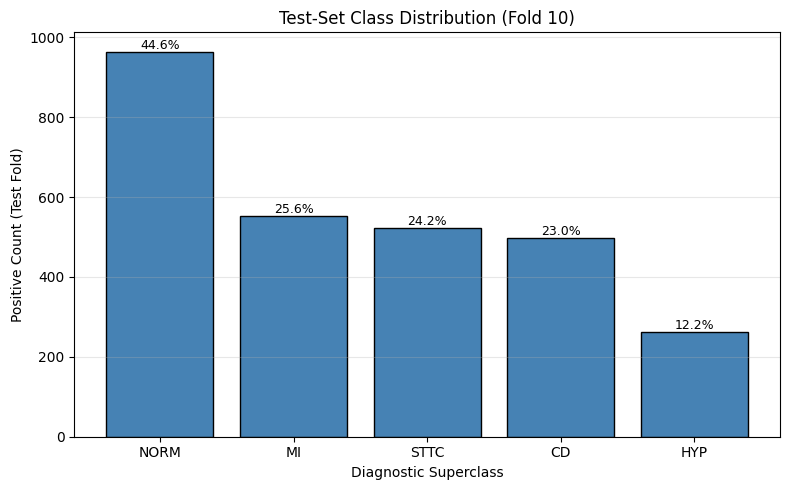

In [9]:
# Section 3.3 — Test-Set Signal Shape & Class Distribution Verification
# ---------------------------------------------------------------------------

_batch_signals, _batch_labels, _batch_ids = next(iter(test_loader))
print(f"Signal batch  shape={tuple(_batch_signals.shape)}  dtype={_batch_signals.dtype}")
print(f"Label  batch  shape={tuple(_batch_labels.shape)}   dtype={_batch_labels.dtype}")
print(f"ID     batch  shape={tuple(_batch_ids.shape)}      dtype={_batch_ids.dtype}")

n_nan = torch.isnan(_batch_signals).sum().item()
n_inf = torch.isinf(_batch_signals).sum().item()
label_range_ok = bool(((_batch_labels == 0) | (_batch_labels == 1)).all())
print(f"\nNaN count in signals   : {n_nan}")
print(f"Inf count in signals   : {n_inf}")
print(f"Labels strictly binary : {label_range_ok}")
assert n_nan == 0 and n_inf == 0, "Test signals contain NaN/Inf — investigate before evaluating."

# Test-fold class distribution (positive count and rate per superclass).
test_label_matrix = label_matrix.loc[splits["test"]]
class_counts = test_label_matrix.sum().astype(int)
class_rates = (class_counts / len(test_label_matrix) * 100).round(2)
class_distribution = pd.DataFrame({"positive_count": class_counts, "positive_rate_pct": class_rates})
print("\nTest-fold class distribution:")
print(class_distribution.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASS_NAMES, class_counts.reindex(CLASS_NAMES), color="steelblue", edgecolor="black")
for bar, rate in zip(bars, class_rates.reindex(CLASS_NAMES)):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{rate:.1f}%",
            ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Diagnostic Superclass")
ax.set_ylabel("Positive Count (Test Fold)")
ax.set_title("Test-Set Class Distribution (Fold 10)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.FIGURES_DIR, "03_test_class_distribution.png"), dpi=300)
plt.show()

## Section 4 — Load Model

The architecture classes below are copied **verbatim** from Notebook 05 — no logic is changed —
so `state_dict` keys line up exactly. Hyperparameters are read from the frozen `TRAINED_CONFIG`
(Section 2.4) rather than re-typed, so the reconstruction is provably identical to what was
trained. `MambaClassifier` additionally exposes `forward(..., return_embedding=True)`, an
evaluation-only addition (no new parameters, no change to the trained forward path) used later for
representation analysis (Section 8).

```
Linear Projection  (N_LEADS -> EMBED_DIM)
      ▼
Stack of Mamba Blocks × N_MAMBA_LAYERS   (pre-norm, residual, official mamba_ssm.Mamba)
      ▼
LayerNorm
      ▼
Global Average Pooling  (mean over time)   <-- "embedding" tapped here
      ▼
Dropout
      ▼
Classification Head  (Linear -> GELU -> Dropout -> Linear)
      ▼
Logits (B, N_CLASSES)
```

In [10]:
# Section 4.1 — Architecture (identical to Notebook 05 v2 — bidirectional + attention pooling)
# ---------------------------------------------------------------------------

class BidirectionalMambaBlock(nn.Module):
    """A pre-norm, residual Mamba block that scans both directions and concatenates.

    Parameters
    ----------
    d_model : int
        Residual-stream / embedding dimension.
    d_state : int
        SSM state expansion factor (official `mamba_ssm.Mamba` parameter).
    d_conv : int
        Local causal-convolution kernel width.
    expand : int
        Inner block expansion factor.
    dropout : float
        Dropout probability applied to the block's output before the residual add.
    """

    def __init__(self, d_model: int, d_state: int, d_conv: int, expand: int, dropout: float,
                 bidirectional: bool = True):
        super().__init__()
        self.bidirectional = bidirectional
        self.norm = nn.LayerNorm(d_model)
        self.mamba_fwd = Mamba(d_model=d_model, d_state=d_state, d_conv=d_conv, expand=expand)
        if bidirectional:
            self.mamba_bwd = Mamba(d_model=d_model, d_state=d_state, d_conv=d_conv, expand=expand)
            self.merge = nn.Linear(2 * d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Apply pre-norm -> Mamba -> dropout -> residual add.

        Parameters
        ----------
        x : torch.Tensor
            Shape `(batch, length, d_model)`.

        Returns
        -------
        torch.Tensor
            Same shape as `x`.
        """
        residual = x
        x = self.norm(x)
        out_fwd = self.mamba_fwd(x)
        if self.bidirectional:
            out_bwd = self.mamba_bwd(torch.flip(x, dims=[1]))
            out_bwd = torch.flip(out_bwd, dims=[1])
            out = self.merge(torch.cat([out_fwd, out_bwd], dim=-1))
        else:
            out = out_fwd
        out = self.dropout(out)
        return residual + out
        
class AttentionPool(nn.Module):
    """Learned additive attention pooling over the time dimension."""

    def __init__(self, d_model: int, hidden_dim: int = 64):
        super().__init__()
        self.scorer = nn.Sequential(
            nn.Linear(d_model, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        scores = self.scorer(x)
        weights = torch.softmax(scores, dim=1)
        return (x * weights).sum(dim=1)

class ClassificationHead(nn.Module):
    """Two-layer MLP classification head producing raw (pre-sigmoid) logits.

    Parameters
    ----------
    in_dim : int
        Input feature dimension (pooled backbone width).
    hidden_dim : int
        Hidden-layer width.
    n_classes : int
        Number of output logits (one per diagnostic superclass).
    dropout : float
        Dropout probability applied after the hidden activation.
    """

    def __init__(self, in_dim: int, hidden_dim: int, n_classes: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, n_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Map pooled features to class logits. `x`: `(batch, in_dim)` -> `(batch, n_classes)`."""
        return self.net(x)


class MambaClassifier(nn.Module):
    """Full supervised Mamba classifier: input projection -> Mamba stack -> pooled head.

    Parameters
    ----------
    n_leads : int
        Number of input channels (ECG leads).
    n_classes : int
        Number of output classes (multi-label).
    embed_dim : int
        Mamba residual-stream width (`d_model`).
    hidden_dim : int
        Classification-head hidden width.
    n_layers : int
        Number of stacked `MambaBlock`s.
    d_state, d_conv, expand : int
        Forwarded to every `mamba_ssm.Mamba` instance.
    dropout : float
        Dropout probability used in both the backbone blocks and the head.
    """

    def __init__(self, n_leads: int, n_classes: int, embed_dim: int, hidden_dim: int,
                 n_layers: int, d_state: int, d_conv: int, expand: int, dropout: float,
                 bidirectional: bool = True, pooling: str = "mean_attention"):
        super().__init__()
        if pooling not in {"mean", "mean_attention"}:
            raise ValueError(f"pooling must be 'mean' or 'mean_attention', got {pooling!r}")
        self.pooling = pooling

        self.input_proj = nn.Linear(n_leads, embed_dim)
        self.blocks = nn.ModuleList([
            BidirectionalMambaBlock(embed_dim, d_state, d_conv, expand, dropout, bidirectional)
            for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

        if pooling == "mean_attention":
            self.attn_pool = AttentionPool(embed_dim)
            head_in_dim = embed_dim * 2
        else:
            self.attn_pool = None
            head_in_dim = embed_dim

        self.head = ClassificationHead(head_in_dim, hidden_dim, n_classes, dropout)

    def forward(self, x: torch.Tensor, return_embedding: bool = False):
        """Classify a batch of ECG signals.

        Parameters
        ----------
        x : torch.Tensor
            Shape `(batch, n_leads, length)` — the raw preprocessed signal layout produced by
            Notebook 02's `PTBXLClassificationDataset`.
        return_embedding : bool
            Evaluation-only flag (Notebook 06 addition; no effect on trained weights or the
            standard forward path). If True, also returns the pooled `(batch, embed_dim)`
            representation used for representation analysis in Section 8.

        Returns
        -------
        torch.Tensor or tuple[torch.Tensor, torch.Tensor]
            Logits of shape `(batch, n_classes)` (apply `sigmoid` for probabilities); if
            `return_embedding` is True, also the pooled embedding of shape `(batch, embed_dim)`.
        """
        x = x.transpose(1, 2)          
        x = self.input_proj(x)         # -> (B, T, embed_dim)
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)

        mean_pooled = x.mean(dim=1)    # (B, embed_dim)
        if self.pooling == "mean_attention":
            attn_pooled = self.attn_pool(x)
            pooled = torch.cat([mean_pooled, attn_pooled], dim=-1)  # (B, 2*embed_dim)
        else:
            pooled = mean_pooled

        x = self.dropout(pooled)
        logits = self.head(x)          # -> (B, n_classes)
        return (logits, pooled) if return_embedding else logits

In [11]:
# Section 4.2 — Instantiate From Frozen Config and Load Weights
# ---------------------------------------------------------------------------

model = MambaClassifier(
    n_leads=CONFIG.N_LEADS,
    n_classes=CONFIG.N_CLASSES,
    embed_dim=TRAINED_CONFIG["EMBED_DIM"],
    hidden_dim=TRAINED_CONFIG["HIDDEN_DIM"],
    n_layers=TRAINED_CONFIG["N_MAMBA_LAYERS"],
    d_state=TRAINED_CONFIG["D_STATE"],
    d_conv=TRAINED_CONFIG["D_CONV"],
    expand=TRAINED_CONFIG["EXPAND"],
    dropout=TRAINED_CONFIG["DROPOUT"],
    bidirectional=TRAINED_CONFIG["BIDIRECTIONAL"],
    pooling=TRAINED_CONFIG["POOLING"],
).to(EVAL_CONFIG.DEVICE)

_checkpoint_path = os.path.join(CHECKPOINT_DIR, "best_mamba.pth")
_state = torch.load(_checkpoint_path, map_location=EVAL_CONFIG.DEVICE)
_missing, _unexpected = model.load_state_dict(_state["model_state_dict"], strict=True)
assert not _missing and not _unexpected, (
    f"Checkpoint/architecture mismatch — missing={_missing}, unexpected={_unexpected}"
)
model.eval()
for p in model.parameters():
    p.requires_grad_(False)  # evaluation only — no gradients are ever taken w.r.t. weights

print(f"Loaded weights from        : {_checkpoint_path}")
print(f"Checkpoint epoch           : {_state.get('epoch', 'n/a')}")
print(f"Model in eval() mode       : {not model.training}")
print(f"All parameters frozen      : {all(not p.requires_grad for p in model.parameters())}")

# Smoke test — forward pass shape check before running full inference.
with torch.no_grad():
    _probe = torch.randn(4, CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH, device=EVAL_CONFIG.DEVICE)
    _out, _emb = model(_probe, return_embedding=True)
assert _out.shape == (4, CONFIG.N_CLASSES), "Model output shape mismatch."
_expected_emb_dim = (
    TRAINED_CONFIG["EMBED_DIM"] * 2
    if TRAINED_CONFIG["POOLING"] == "mean_attention"
    else TRAINED_CONFIG["EMBED_DIM"]
)
assert _emb.shape == (4, _expected_emb_dim), "Embedding shape mismatch."
print(f"\nSmoke test  input={tuple(_probe.shape)}  ->  logits={tuple(_out.shape)}, "
      f"embedding={tuple(_emb.shape)}")
print("[PASS] Forward pass shape check.")

Loaded weights from        : /kaggle/input/notebooks/shamsuzzamanhisham/ptb-xl-ecg-supervised-mamba-trainin-v2-improved/mamba_supervised_v2_outputs/checkpoints/best_mamba.pth
Checkpoint epoch           : 11
Model in eval() mode       : True
All parameters frozen      : True

Smoke test  input=(4, 12, 1000)  ->  logits=(4, 5), embedding=(4, 256)
[PASS] Forward pass shape check.


In [12]:
# Section 4.3 — Model Summary
# ---------------------------------------------------------------------------

def summarize_model(model: nn.Module) -> pd.DataFrame:
    """Build a per-top-level-module parameter-count summary table.

    Parameters
    ----------
    model : nn.Module
        Model to summarize.

    Returns
    -------
    pandas.DataFrame
        One row per top-level named child module, plus a totals row.
    """
    rows = []
    for name, module in model.named_children():
        n = sum(p.numel() for p in module.parameters())
        n_trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
        rows.append({"module": name, "type": module.__class__.__name__,
                      "parameters": n, "trainable_parameters": n_trainable})
    df = pd.DataFrame(rows)
    total = pd.DataFrame([{
        "module": "TOTAL", "type": "-",
        "parameters": df["parameters"].sum(),
        "trainable_parameters": df["trainable_parameters"].sum(),
    }])
    return pd.concat([df, total], ignore_index=True)


model_summary = summarize_model(model)
n_params = int(model_summary.loc[model_summary["module"] == "TOTAL", "parameters"].item())
n_trainable = int(model_summary.loc[model_summary["module"] == "TOTAL", "trainable_parameters"].item())
model_size_mb = sum(p.numel() * p.element_size() for p in model.state_dict().values()) / (1024 ** 2)

print("Model summary (top-level modules):")
print(model_summary.to_string(index=False))
print(f"\nTotal parameters     : {n_params:,}")
print(f"Trainable parameters : {n_trainable:,}  (0 expected — model is fully frozen for evaluation)")
print(f"Model size on disk   : {model_size_mb:.2f} MB (state_dict, fp32)")

Model summary (top-level modules):
    module               type  parameters  trainable_parameters
input_proj             Linear        1664                     0
    blocks         ModuleList     1596672                     0
final_norm          LayerNorm         256                     0
   dropout            Dropout           0                     0
 attn_pool      AttentionPool        8321                     0
      head ClassificationHead       67077                     0
     TOTAL                  -     1673990                     0

Total parameters     : 1,673,990
Trainable parameters : 0  (0 expected — model is fully frozen for evaluation)
Model size on disk   : 6.39 MB (state_dict, fp32)


## Section 5 — Inference

`InferenceEngine` runs a single frozen forward pass over the test loader and collects everything
downstream sections need: per-class probabilities, thresholded predictions, ground truth, and a
per-sample confidence score. Predictions are then saved for later reuse.

In [13]:
# Section 5.1 — InferenceEngine
# ---------------------------------------------------------------------------

@dataclass
class InferenceResults:
    """Container for one complete inference pass over a DataLoader.

    Attributes
    ----------
    ecg_ids : np.ndarray
        Shape `(N,)` — record identifiers, in loader iteration order.
    probs : np.ndarray
        Shape `(N, C)` — sigmoid class probabilities.
    preds : np.ndarray
        Shape `(N, C)` — binarized predictions at `EVAL_CONFIG.DECISION_THRESHOLD`.
    labels : np.ndarray
        Shape `(N, C)` — ground-truth multi-hot labels.
    confidences : np.ndarray
        Shape `(N,)` — per-sample confidence in `[0, 1]`, averaged distance-from-boundary
        across classes: `mean(2 * |p - 0.5|)`.
    """
    ecg_ids: np.ndarray
    probs: np.ndarray
    preds: np.ndarray
    labels: np.ndarray
    confidences: np.ndarray


class InferenceEngine:
    """Runs batched, gradient-free inference over a DataLoader and collects results.

    Parameters
    ----------
    model : nn.Module
        Frozen, `eval()`-mode classifier returning multi-label logits.
    device : torch.device
        Device to run inference on.
    threshold : float
        Decision threshold used to binarize sigmoid probabilities into predicted labels.
    """

    def __init__(self, model: nn.Module, device: torch.device, threshold=0.5):
        self.model = model
        self.device = device
        # `threshold` may be a scalar (flat cutoff for every class) or an array of shape (C,)
        # with one tuned cutoff per class (see the per-class threshold loading below).
        self.threshold = threshold

    @torch.no_grad()
    def run(self, loader: DataLoader) -> InferenceResults:
        """Execute one full forward pass over `loader`.

        Parameters
        ----------
        loader : DataLoader
            Yields `(signal, label, ecg_id)` batches, as produced by Notebook 02.

        Returns
        -------
        InferenceResults
        """
        self.model.eval()
        all_probs, all_labels, all_ids = [], [], []

        for signals, labels, ecg_ids in tqdm(loader, desc="inference", leave=False):
            signals = signals.to(self.device, non_blocking=True)
            logits = self.model(signals)
            probs = torch.sigmoid(logits).cpu().numpy()
            all_probs.append(probs)
            all_labels.append(labels.numpy())
            all_ids.append(ecg_ids.numpy())

        probs = np.concatenate(all_probs, axis=0).astype(np.float32)
        labels = np.concatenate(all_labels, axis=0).astype(np.int32)
        ecg_ids = np.concatenate(all_ids, axis=0).astype(np.int64)
        preds = (probs >= np.asarray(self.threshold)).astype(np.int32)  # broadcasts scalar or (C,) array
        confidences = np.mean(2.0 * np.abs(probs - 0.5), axis=1).astype(np.float32)

        return InferenceResults(ecg_ids=ecg_ids, probs=probs, preds=preds,
                                 labels=labels, confidences=confidences)


# ---- Per-class tuned decision thresholds (from Notebook 05, Section 11.3) -------------------
# Notebook 05 grid-searches, per class, the threshold that maximizes F1 on the *validation* fold
# and saves it to thresholds.json. A blanket 0.5 cutoff is a poor default for imbalanced classes
# (e.g. HYP at ~12% prevalence) whose optimal operating point sits well away from 0.5. Use the
# tuned thresholds here instead, falling back to the flat EVAL_CONFIG.DECISION_THRESHOLD only if
# thresholds.json isn't present.
_thresholds_path = os.path.join(CHECKPOINT_DIR, "thresholds.json")
if os.path.exists(_thresholds_path):
    with open(_thresholds_path) as _f:
        _tuned_thresholds = json.load(_f)
    decision_threshold = np.array([_tuned_thresholds[cls] for cls in CLASS_NAMES], dtype=np.float32)
    print(f"Loaded per-class tuned thresholds from {_thresholds_path}:")
    for _cls, _t in zip(CLASS_NAMES, decision_threshold):
        print(f"  {_cls:6s}: {_t:.2f}")
else:
    decision_threshold = EVAL_CONFIG.DECISION_THRESHOLD
    print(f"thresholds.json not found in {CHECKPOINT_DIR} -- falling back to a flat "
          f"{EVAL_CONFIG.DECISION_THRESHOLD} threshold for every class. Re-run Notebook 05's "
          f"Section 11.3 (per-class threshold tuning) and re-attach its checkpoint output to "
          f"get properly tuned, per-class thresholds here.")

inference_engine = InferenceEngine(model, EVAL_CONFIG.DEVICE, decision_threshold)
results = inference_engine.run(test_loader)

print(f"Inference complete on {len(results.ecg_ids)} test records.")
print(f"probs shape       : {results.probs.shape}")
print(f"preds shape       : {results.preds.shape}")
print(f"labels shape      : {results.labels.shape}")
print(f"confidences shape : {results.confidences.shape}")
print(f"Mean confidence   : {results.confidences.mean():.4f}")

Loaded per-class tuned thresholds from /kaggle/input/notebooks/shamsuzzamanhisham/ptb-xl-ecg-supervised-mamba-trainin-v2-improved/mamba_supervised_v2_outputs/checkpoints/thresholds.json:
  NORM  : 0.65
  MI    : 0.55
  STTC  : 0.45
  CD    : 0.85
  HYP   : 0.70


inference:   0%|          | 0/17 [00:03<?, ?it/s]

Inference complete on 2163 test records.
probs shape       : (2163, 5)
preds shape       : (2163, 5)
labels shape      : (2163, 5)
confidences shape : (2163,)
Mean confidence   : 0.6964


In [14]:
# Section 5.2 — Save Predictions
# ---------------------------------------------------------------------------

predictions_df = pd.DataFrame({"ecg_id": results.ecg_ids, "confidence": results.confidences})
for j, cls in enumerate(CLASS_NAMES):
    predictions_df[f"{cls}_prob"] = results.probs[:, j]
    predictions_df[f"{cls}_pred"] = results.preds[:, j]
    predictions_df[f"{cls}_true"] = results.labels[:, j]

predictions_path = os.path.join(EVAL_CONFIG.PREDICTIONS_DIR, "predictions.csv")
predictions_df.to_csv(predictions_path, index=False)
print(f"Saved predictions -> {predictions_path}")
predictions_df.head()

Saved predictions -> ./mamba_evaluation_outputs/predictions/predictions.csv


,ecg_id,confidence,NORM_prob,NORM_pred,NORM_true,MI_prob,MI_pred,MI_true,STTC_prob,STTC_pred,STTC_true,CD_prob,CD_pred,CD_true,HYP_prob,HYP_pred,HYP_true
0,9,0.755988,0.951594,1,1,0.135986,0,0,0.058313,0,0,0.188352,0,0,0.178974,0,0
1,38,0.617458,0.583383,0,1,0.113292,0,0,0.108903,0,0,0.938452,1,0,0.255994,0,0
2,40,0.723537,0.943007,1,1,0.045326,0,0,0.048548,0,0,0.164327,0,0,0.375963,0,0
3,57,0.848096,0.979690,1,1,0.071279,0,0,0.043258,0,0,0.082408,0,0,0.162504,0,0
4,59,0.760803,0.964586,1,1,0.066125,0,0,0.053700,0,0,0.250217,0,0,0.192537,0,0


## Section 6 — Evaluation Metrics

`Evaluator` computes the complete metric battery specified for this notebook: threshold-free
ranking metrics (AUROC, Average Precision) computed on probabilities, and threshold-dependent
metrics (F1, precision, recall, specificity, sensitivity, balanced accuracy, Hamming loss, subset
accuracy) computed on the `EVAL_CONFIG.DECISION_THRESHOLD`-binarized predictions — both overall
(macro/micro) and per class.

In [15]:
# Section 6.1 — Evaluator
# ---------------------------------------------------------------------------

class Evaluator:
    """Computes the full multi-label evaluation-metric battery for one inference pass.

    Parameters
    ----------
    class_names : list[str]
        Ordered diagnostic superclass names, matching the column order of `probs`/`preds`/`labels`.
    threshold : float
        Decision threshold already used to produce `results.preds` (kept for reporting only).
    """

    def __init__(self, class_names: List[str], threshold: float = 0.5):
        self.class_names = class_names
        self.threshold = threshold

    @staticmethod
    def _safe_auroc(y_true_col: np.ndarray, y_score_col: np.ndarray) -> float:
        """Per-class AUROC, returning NaN if a column has only one label value present."""
        if len(np.unique(y_true_col)) < 2:
            return float("nan")
        return float(roc_auc_score(y_true_col, y_score_col))

    def per_class_table(self, results: InferenceResults) -> pd.DataFrame:
        """Build the per-class metrics table (AUROC, AP, F1, precision, recall, specificity).

        Parameters
        ----------
        results : InferenceResults

        Returns
        -------
        pandas.DataFrame
            One row per class.
        """
        y_true, y_prob, y_pred = results.labels, results.probs, results.preds
        mcm = multilabel_confusion_matrix(y_true, y_pred)  # (C, 2, 2): [[tn, fp], [fn, tp]]

        rows = []
        for j, cls in enumerate(self.class_names):
            tn, fp, fn, tp = mcm[j].ravel()
            sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
            specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
            rows.append({
                "class": cls,
                "n_positive": int(y_true[:, j].sum()),
                "auroc": self._safe_auroc(y_true[:, j], y_prob[:, j]),
                "average_precision": average_precision_score(y_true[:, j], y_prob[:, j])
                    if len(np.unique(y_true[:, j])) > 1 else float("nan"),
                "f1": f1_score(y_true[:, j], y_pred[:, j], zero_division=0),
                "precision": precision_score(y_true[:, j], y_pred[:, j], zero_division=0),
                "recall_sensitivity": sensitivity,
                "specificity": specificity,
                "balanced_accuracy": (sensitivity + specificity) / 2
                    if not (np.isnan(sensitivity) or np.isnan(specificity)) else float("nan"),
            })
        return pd.DataFrame(rows)

    def overall_metrics(self, results: InferenceResults, per_class: pd.DataFrame) -> Dict[str, float]:
        """Aggregate macro/micro overall metrics.

        Parameters
        ----------
        results : InferenceResults
        per_class : pandas.DataFrame
            Output of `per_class_table`, reused to avoid recomputing per-class values.

        Returns
        -------
        dict[str, float]
        """
        y_true, y_prob, y_pred = results.labels, results.probs, results.preds
        return {
            "macro_auroc": float(np.nanmean(per_class["auroc"])),
            "micro_auroc": float(roc_auc_score(y_true, y_prob, average="micro")),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "micro_f1": float(f1_score(y_true, y_pred, average="micro", zero_division=0)),
            "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "specificity_macro": float(np.nanmean(per_class["specificity"])),
            "sensitivity_macro": float(np.nanmean(per_class["recall_sensitivity"])),
            "balanced_accuracy_macro": float(np.nanmean(per_class["balanced_accuracy"])),
            "average_precision_macro": float(np.nanmean(per_class["average_precision"])),
            "average_precision_micro": float(average_precision_score(y_true, y_prob, average="micro")),
            "hamming_loss": float(hamming_loss(y_true, y_pred)),
            "subset_accuracy": float(accuracy_score(y_true, y_pred)),
        }

    def evaluate(self, results: InferenceResults) -> Tuple[Dict[str, float], pd.DataFrame]:
        """Compute overall and per-class metrics in one call.

        Returns
        -------
        tuple[dict[str, float], pandas.DataFrame]
            `(overall_metrics, per_class_table)`.
        """
        per_class = self.per_class_table(results)
        overall = self.overall_metrics(results, per_class)
        return overall, per_class


evaluator = Evaluator(CLASS_NAMES, decision_threshold)  # per-class array if thresholds.json was found
overall_metrics, per_class_metrics = evaluator.evaluate(results)

print("Overall test-set metrics:")
for k, v in overall_metrics.items():
    print(f"  {k:28s}: {v:.4f}")

print("\nPer-class metrics:")
per_class_metrics.round(4)

Overall test-set metrics:
  macro_auroc                 : 0.9196
  micro_auroc                 : 0.9267
  macro_f1                    : 0.7309
  micro_f1                    : 0.7722
  precision_macro             : 0.7278
  recall_macro                : 0.7409
  specificity_macro           : 0.9071
  sensitivity_macro           : 0.7409
  balanced_accuracy_macro     : 0.8240
  average_precision_macro     : 0.8026
  average_precision_micro     : 0.8480
  hamming_loss                : 0.1203
  subset_accuracy             : 0.6038

Per-class metrics:


,class,n_positive,auroc,average_precision,f1,precision,recall_sensitivity,specificity,balanced_accuracy
0,NORM,964,0.9428,0.9218,0.8567,0.8128,0.9056,0.8324,0.8690
1,MI,553,0.9298,0.8498,0.7566,0.7384,0.7758,0.9056,0.8407
2,STTC,523,0.9342,0.8258,0.7776,0.7376,0.8222,0.9067,0.8644
3,CD,498,0.9190,0.8472,0.7500,0.8538,0.6687,0.9658,0.8172
4,HYP,263,0.8723,0.5683,0.5138,0.4965,0.5323,0.9253,0.7288


In [16]:
# Section 6.2 — Classification Report and Metrics Export
# ---------------------------------------------------------------------------

report_text = classification_report(
    results.labels, results.preds, target_names=CLASS_NAMES, zero_division=0,
)
print(report_text)

metrics_path = os.path.join(EVAL_CONFIG.TABLES_DIR, "metrics.csv")
overall_row = pd.DataFrame([{"class": "OVERALL", **overall_metrics}])
metrics_export = pd.concat([per_class_metrics, overall_row], ignore_index=True)
metrics_export.to_csv(metrics_path, index=False)
print(f"\nSaved metrics -> {metrics_path}")

              precision    recall  f1-score   support

        NORM       0.81      0.91      0.86       964
          MI       0.74      0.78      0.76       553
        STTC       0.74      0.82      0.78       523
          CD       0.85      0.67      0.75       498
         HYP       0.50      0.53      0.51       263

   micro avg       0.76      0.79      0.77      2801
   macro avg       0.73      0.74      0.73      2801
weighted avg       0.76      0.79      0.77      2801
 samples avg       0.78      0.81      0.78      2801


Saved metrics -> ./mamba_evaluation_outputs/tables/metrics.csv


## Section 7 — Visualization

`VisualizationEngine` produces publication-quality (300 DPI), consistently-styled figures for
every curve/plot required: ROC, precision-recall, raw and normalized confusion matrices,
prediction-probability distributions, the confidence histogram, and per-class calibration curves.
Every figure is saved to `EVAL_CONFIG.FIGURES_DIR` and displayed inline.

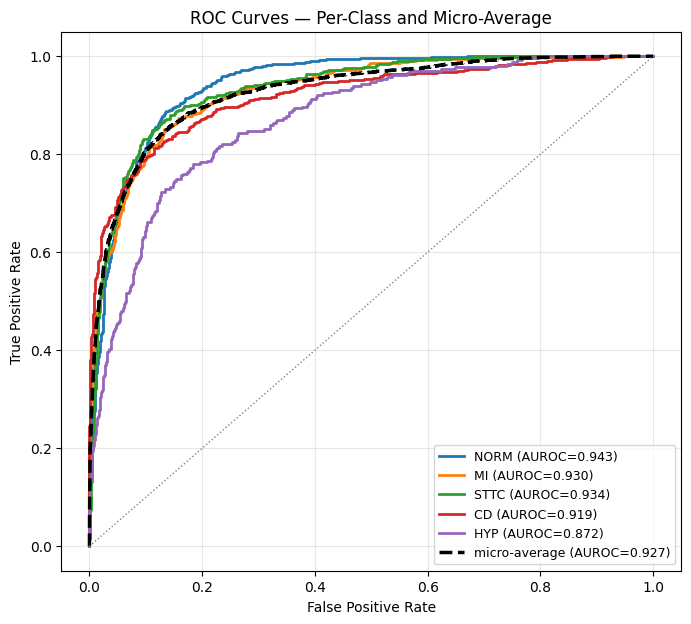

In [17]:
# Section 7.1 — VisualizationEngine
# ---------------------------------------------------------------------------

class VisualizationEngine:
    """Generates and persists publication-quality evaluation figures.

    Parameters
    ----------
    class_names : list[str]
        Ordered diagnostic superclass names.
    figures_dir : str
        Directory that receives every saved `.png`.
    dpi : int
        Resolution used for all saved figures.
    """

    _PALETTE = plt.cm.tab10(np.linspace(0, 1, 10))

    def __init__(self, class_names: List[str], figures_dir: str, dpi: int = 300):
        self.class_names = class_names
        self.figures_dir = figures_dir
        self.dpi = dpi

    def _save(self, fig: plt.Figure, filename: str) -> str:
        path = os.path.join(self.figures_dir, filename)
        fig.savefig(path, dpi=self.dpi, bbox_inches="tight")
        return path

    def plot_roc_curves(self, y_true: np.ndarray, y_prob: np.ndarray) -> plt.Figure:
        """One ROC curve per class plus micro-average, with AUROC in the legend."""
        fig, ax = plt.subplots(figsize=(8, 7))
        for j, cls in enumerate(self.class_names):
            if len(np.unique(y_true[:, j])) < 2:
                continue
            fpr, tpr, _ = roc_curve(y_true[:, j], y_prob[:, j])
            auc = roc_auc_score(y_true[:, j], y_prob[:, j])
            ax.plot(fpr, tpr, color=self._PALETTE[j], lw=2, label=f"{cls} (AUROC={auc:.3f})")
        fpr_micro, tpr_micro, _ = roc_curve(y_true.ravel(), y_prob.ravel())
        auc_micro = roc_auc_score(y_true, y_prob, average="micro")
        ax.plot(fpr_micro, tpr_micro, color="black", lw=2.5, linestyle="--",
                label=f"micro-average (AUROC={auc_micro:.3f})")
        ax.plot([0, 1], [0, 1], color="gray", lw=1, linestyle=":")
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.set_title("ROC Curves — Per-Class and Micro-Average")
        ax.legend(loc="lower right", fontsize=9)
        ax.grid(alpha=0.3)
        self._save(fig, "roc_curve.png")
        return fig

    def plot_pr_curves(self, y_true: np.ndarray, y_prob: np.ndarray) -> plt.Figure:
        """One precision-recall curve per class plus micro-average, with AP in the legend."""
        fig, ax = plt.subplots(figsize=(8, 7))
        for j, cls in enumerate(self.class_names):
            if len(np.unique(y_true[:, j])) < 2:
                continue
            precision, recall, _ = precision_recall_curve(y_true[:, j], y_prob[:, j])
            ap = average_precision_score(y_true[:, j], y_prob[:, j])
            ax.plot(recall, precision, color=self._PALETTE[j], lw=2, label=f"{cls} (AP={ap:.3f})")
        precision_micro, recall_micro, _ = precision_recall_curve(y_true.ravel(), y_prob.ravel())
        ap_micro = average_precision_score(y_true, y_prob, average="micro")
        ax.plot(recall_micro, precision_micro, color="black", lw=2.5, linestyle="--",
                label=f"micro-average (AP={ap_micro:.3f})")
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.set_title("Precision-Recall Curves — Per-Class and Micro-Average")
        ax.legend(loc="lower left", fontsize=9)
        ax.grid(alpha=0.3)
        self._save(fig, "pr_curve.png")
        return fig

    def plot_confusion_matrices(self, y_true: np.ndarray, y_pred: np.ndarray,
                                 normalize: bool = False) -> plt.Figure:
        """A grid of per-class binary confusion matrices (positive vs. negative for that class).

        Parameters
        ----------
        normalize : bool
            If True, rows are normalized to sum to 1 (recall-style normalized confusion matrix).
        """
        mcm = multilabel_confusion_matrix(y_true, y_pred)
        n = len(self.class_names)
        ncols = min(n, 3)
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4 * nrows))
        axes = np.atleast_1d(axes).ravel()
        for j, cls in enumerate(self.class_names):
            cm_j = mcm[j].astype(float)
            if normalize:
                row_sums = cm_j.sum(axis=1, keepdims=True)
                row_sums[row_sums == 0] = 1.0
                cm_j = cm_j / row_sums
            ax = axes[j]
            im = ax.imshow(cm_j, cmap="Blues", vmin=0, vmax=1 if normalize else None)
            fmt = ".2f" if normalize else "d"
            for r in range(2):
                for c in range(2):
                    val = cm_j[r, c]
                    text = f"{val:{fmt}}" if normalize else f"{int(val)}"
                    ax.text(c, r, text, ha="center", va="center",
                            color="white" if val > cm_j.max() / 2 else "black", fontsize=11)
            ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
            ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
            ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
            ax.set_title(cls)
        for k in range(n, len(axes)):
            axes[k].axis("off")
        fig.suptitle("Normalized Confusion Matrices" if normalize else "Confusion Matrices", y=1.02)
        fig.tight_layout()
        self._save(fig, "confusion_matrix_normalized.png" if normalize else "confusion_matrix.png")
        return fig

    def plot_prediction_distribution(self, y_prob: np.ndarray) -> plt.Figure:
        """Histogram of predicted probabilities, one subplot per class."""
        n = len(self.class_names)
        fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.5), sharey=True)
        axes = np.atleast_1d(axes)
        for j, cls in enumerate(self.class_names):
            axes[j].hist(y_prob[:, j], bins=30, color=self._PALETTE[j], edgecolor="black", alpha=0.85)
            axes[j].axvline(0.5, color="red", linestyle="--", lw=1)
            axes[j].set_title(cls)
            axes[j].set_xlabel("Predicted Probability")
        axes[0].set_ylabel("Count")
        fig.suptitle("Prediction Probability Distribution by Class", y=1.03)
        fig.tight_layout()
        self._save(fig, "prediction_distribution.png")
        return fig

    def plot_confidence_histogram(self, confidences: np.ndarray) -> plt.Figure:
        """Histogram of the per-sample overall confidence score."""
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.hist(confidences, bins=30, color="darkslateblue", edgecolor="black", alpha=0.85)
        ax.axvline(confidences.mean(), color="red", linestyle="--", lw=1.5,
                   label=f"mean={confidences.mean():.3f}")
        ax.set_xlabel("Confidence  (mean 2|p - 0.5| across classes)")
        ax.set_ylabel("Count")
        ax.set_title("Prediction Confidence Distribution")
        ax.legend()
        ax.grid(alpha=0.3)
        self._save(fig, "confidence_distribution.png")
        return fig

    def plot_calibration_curves(self, y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> plt.Figure:
        """Per-class reliability diagrams (predicted probability vs. observed frequency)."""
        n = len(self.class_names)
        ncols = min(n, 3)
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4 * nrows))
        axes = np.atleast_1d(axes).ravel()
        for j, cls in enumerate(self.class_names):
            ax = axes[j]
            if len(np.unique(y_true[:, j])) < 2:
                ax.set_title(f"{cls} (single class in test fold)")
                ax.axis("off")
                continue
            frac_pos, mean_pred = calibration_curve(y_true[:, j], y_prob[:, j], n_bins=n_bins, strategy="uniform")
            ax.plot(mean_pred, frac_pos, marker="o", color=self._PALETTE[j], label=cls)
            ax.plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1)
            ax.set_xlabel("Mean Predicted Probability")
            ax.set_ylabel("Observed Frequency")
            ax.set_title(cls)
            ax.grid(alpha=0.3)
        for k in range(n, len(axes)):
            axes[k].axis("off")
        fig.suptitle("Calibration Curves (Reliability Diagrams)", y=1.02)
        fig.tight_layout()
        self._save(fig, "calibration_curve.png")
        return fig


viz_engine = VisualizationEngine(CLASS_NAMES, EVAL_CONFIG.FIGURES_DIR)
_ = viz_engine.plot_roc_curves(results.labels, results.probs)
plt.show()

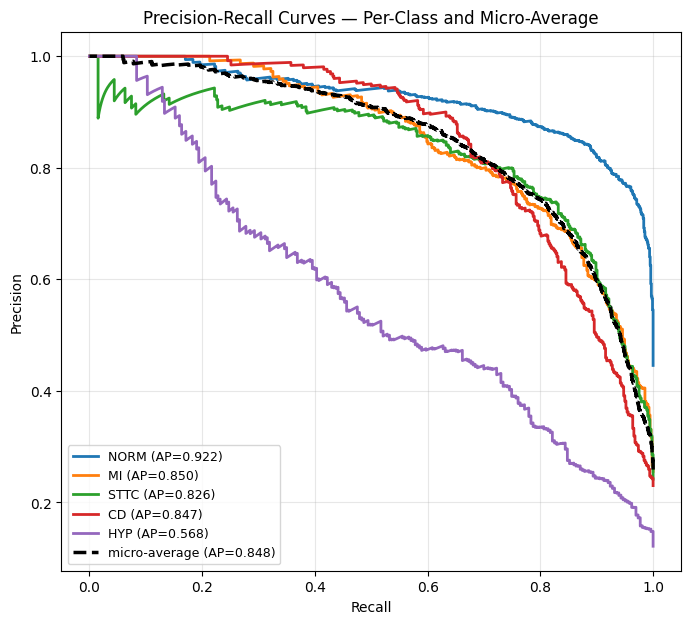

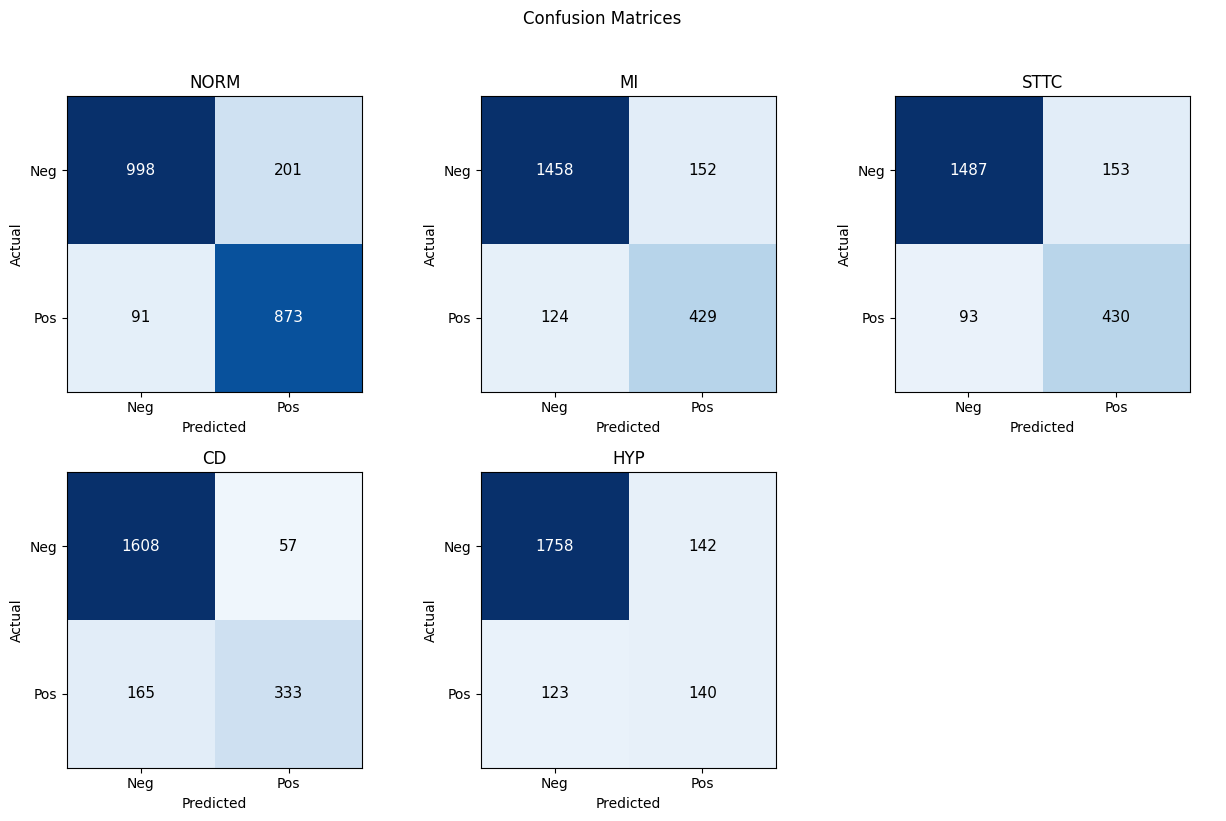

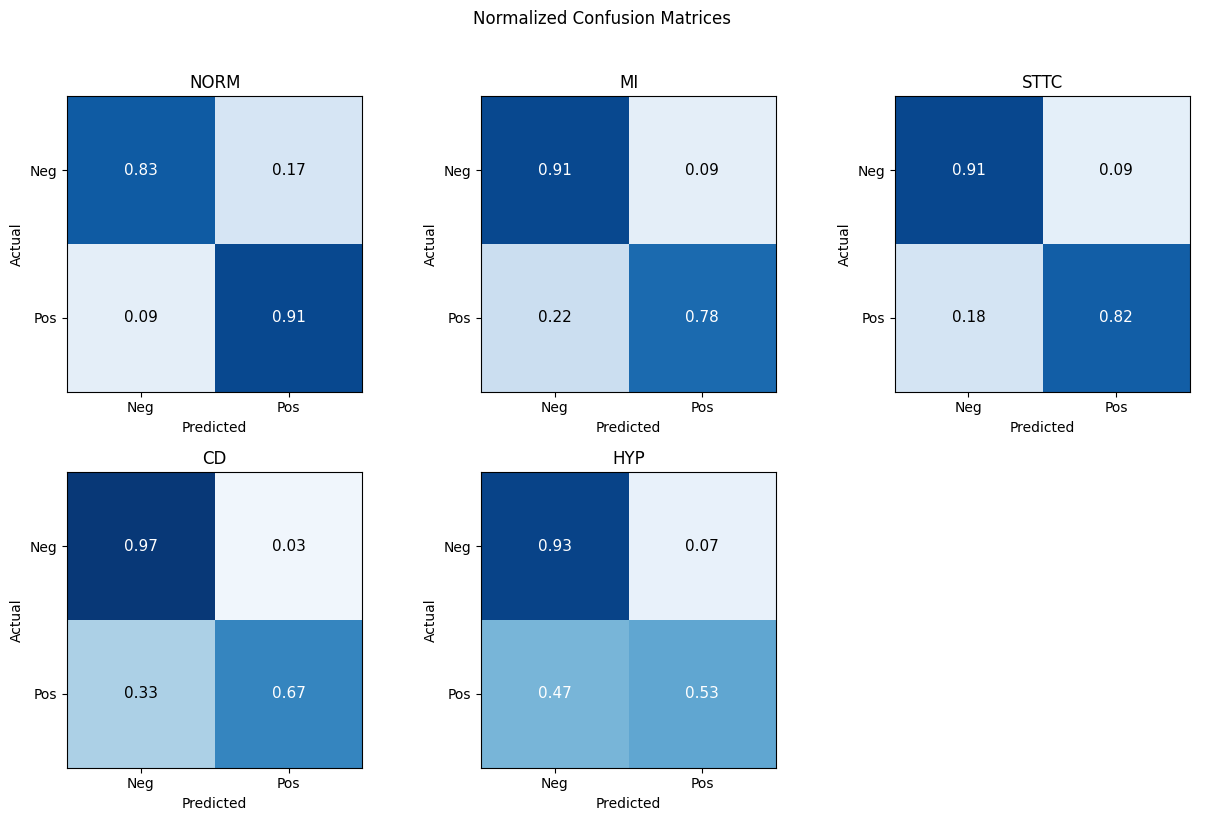

In [18]:
# Section 7.2 — Precision-Recall and Confusion Matrices
# ---------------------------------------------------------------------------

_ = viz_engine.plot_pr_curves(results.labels, results.probs)
plt.show()

_ = viz_engine.plot_confusion_matrices(results.labels, results.preds, normalize=False)
plt.show()

_ = viz_engine.plot_confusion_matrices(results.labels, results.preds, normalize=True)
plt.show()

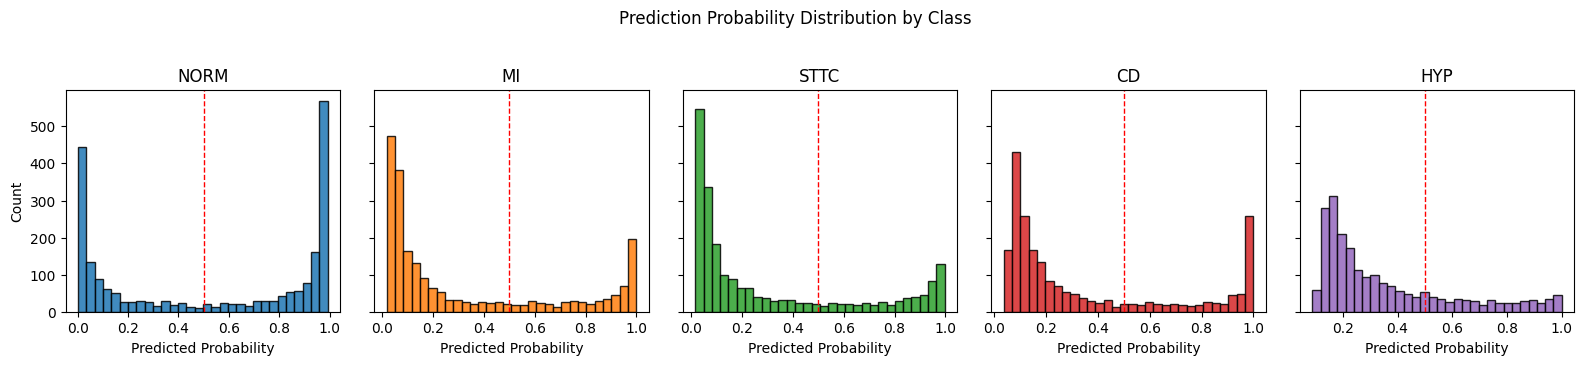

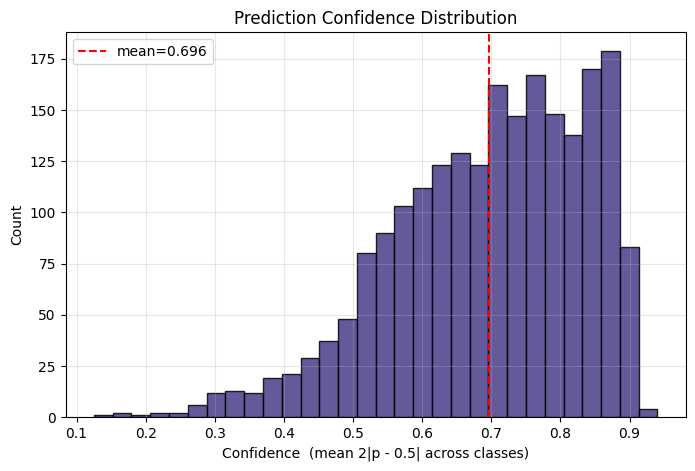

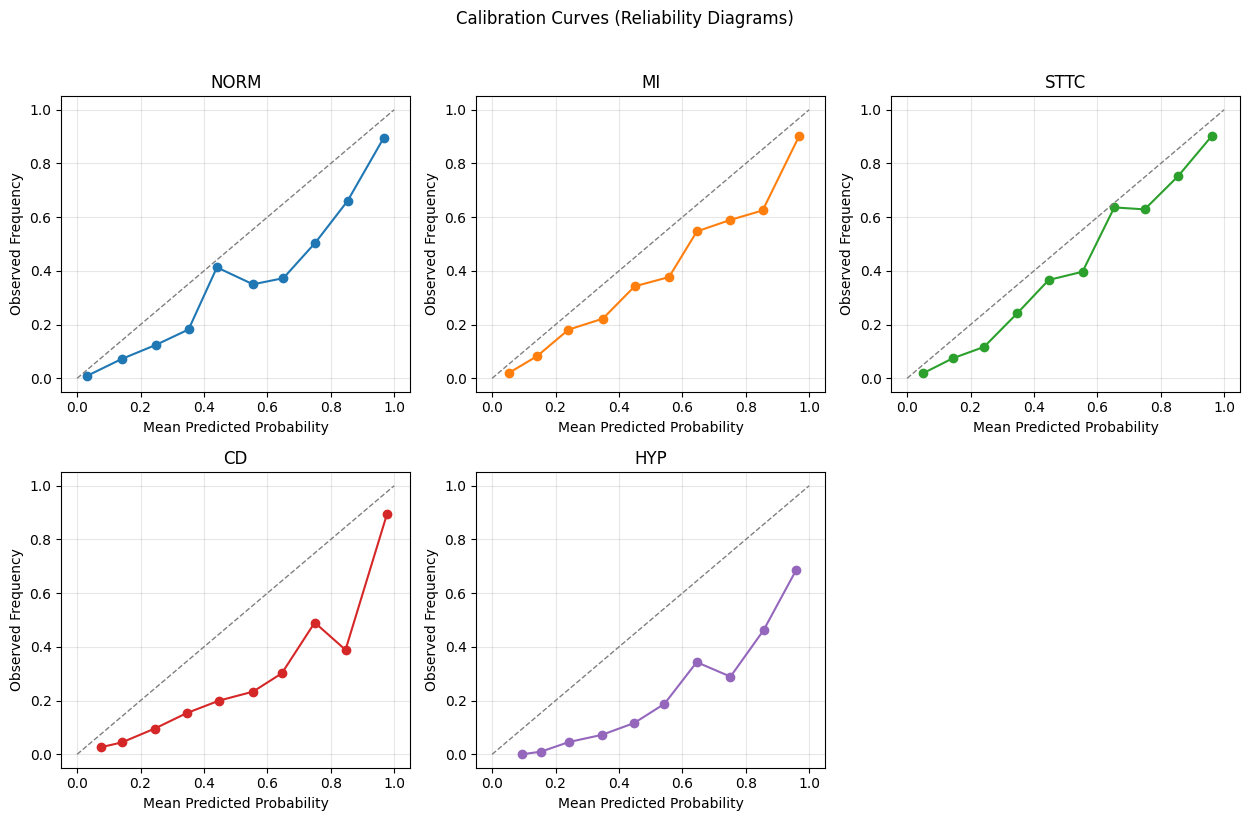

In [19]:
# Section 7.3 — Distribution, Confidence, and Calibration
# ---------------------------------------------------------------------------

_ = viz_engine.plot_prediction_distribution(results.probs)
plt.show()

_ = viz_engine.plot_confidence_histogram(results.confidences)
plt.show()

_ = viz_engine.plot_calibration_curves(results.labels, results.probs)
plt.show()

In [20]:
# Section 7.4 — Confusion Matrix Export (CSV)
# ---------------------------------------------------------------------------

mcm = multilabel_confusion_matrix(results.labels, results.preds)
cm_rows = []
for j, cls in enumerate(CLASS_NAMES):
    tn, fp, fn, tp = mcm[j].ravel()
    cm_rows.append({"class": cls, "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})
confusion_matrix_df = pd.DataFrame(cm_rows)
cm_path = os.path.join(EVAL_CONFIG.TABLES_DIR, "confusion_matrix.csv")
confusion_matrix_df.to_csv(cm_path, index=False)
print(f"Saved confusion matrix -> {cm_path}")
confusion_matrix_df

Saved confusion matrix -> ./mamba_evaluation_outputs/tables/confusion_matrix.csv


,class,tn,fp,fn,tp
0,NORM,998,201,91,873
1,MI,1458,152,124,429
2,STTC,1487,153,93,430
3,CD,1608,57,165,333
4,HYP,1758,142,123,140


## Section 8 — Representation Analysis

Extracts the pooled `(embed_dim,)` representation `MambaClassifier` computes just before its
classification head (global-average-pooled Mamba output, Section 4's `return_embedding=True`
tap) for every test-set record, then projects it to 2D with PCA, t-SNE, and UMAP to inspect
whether the learned representation space separates diagnostic superclasses geometrically — a
property distinct from, and complementary to, the raw classification metrics above.

In [21]:
# Section 8.1 — Extract Embeddings
# ---------------------------------------------------------------------------

@torch.no_grad()
def extract_embeddings(model: nn.Module, loader: DataLoader, device: torch.device
                        ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Run a frozen forward pass collecting pooled embeddings alongside labels/ids.

    Parameters
    ----------
    model : nn.Module
        Must support `forward(x, return_embedding=True)`.
    loader : DataLoader
    device : torch.device

    Returns
    -------
    tuple[np.ndarray, np.ndarray, np.ndarray]
        `(embeddings (N, embed_dim), labels (N, C), ecg_ids (N,))`.
    """
    model.eval()
    all_emb, all_labels, all_ids = [], [], []
    for signals, labels, ecg_ids in tqdm(loader, desc="embeddings", leave=False):
        signals = signals.to(device, non_blocking=True)
        _, emb = model(signals, return_embedding=True)
        all_emb.append(emb.cpu().numpy())
        all_labels.append(labels.numpy())
        all_ids.append(ecg_ids.numpy())
    return (np.concatenate(all_emb, axis=0).astype(np.float32),
            np.concatenate(all_labels, axis=0).astype(np.int32),
            np.concatenate(all_ids, axis=0).astype(np.int64))


embeddings, embedding_labels, embedding_ids = extract_embeddings(model, test_loader, EVAL_CONFIG.DEVICE)
print(f"Embeddings extracted : {embeddings.shape}")

embeddings_path = os.path.join(EVAL_CONFIG.EMBEDDINGS_DIR, "feature_embeddings.npy")
np.save(embeddings_path, embeddings)
print(f"Saved embeddings -> {embeddings_path}")

# Subsample for the more expensive t-SNE/UMAP projections (test fold already modest; this is a
# no-op safety cap in case the fold ever grows).
_rng = np.random.default_rng(EVAL_CONFIG.RANDOM_SEED)
if len(embeddings) > EVAL_CONFIG.MAX_EMBEDDING_SAMPLES:
    _sub_idx = _rng.choice(len(embeddings), size=EVAL_CONFIG.MAX_EMBEDDING_SAMPLES, replace=False)
else:
    _sub_idx = np.arange(len(embeddings))
emb_sub = embeddings[_sub_idx]
labels_sub = embedding_labels[_sub_idx]
print(f"Using {len(emb_sub)} samples for t-SNE/UMAP projections.")

embeddings:   0%|          | 0/17 [00:00<?, ?it/s]

Embeddings extracted : (2163, 256)
Saved embeddings -> ./mamba_evaluation_outputs/embeddings/feature_embeddings.npy
Using 2163 samples for t-SNE/UMAP projections.


In [22]:
# Section 8.2 — Dominant-Class Color Assignment for Multi-Label Plots
# ---------------------------------------------------------------------------
# A record can carry multiple positive superclasses; for 2D scatter coloring we assign each
# point its first positive class (fixed CLASS_NAMES priority order) or "NONE" if all-negative
# (should not occur post-filtering, but handled defensively).

def dominant_class(label_row: np.ndarray, class_names: List[str]) -> str:
    """Return the first positive class name in `class_names` priority order, or 'NONE'."""
    positive = np.where(label_row > 0.5)[0]
    return class_names[positive[0]] if len(positive) else "NONE"


dominant_labels_sub = np.array([dominant_class(row, CLASS_NAMES) for row in labels_sub])
_class_order = CLASS_NAMES + ["NONE"]
_color_map = {c: plt.cm.tab10(i) for i, c in enumerate(_class_order)}


def scatter_by_class(ax, xy: np.ndarray, dominant: np.ndarray, title: str) -> None:
    """Scatter a 2D projection colored by dominant diagnostic superclass."""
    for c in _class_order:
        mask = dominant == c
        if not mask.any():
            continue
        ax.scatter(xy[mask, 0], xy[mask, 1], s=10, alpha=0.7, color=_color_map[c], label=c)
    ax.set_title(title)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(markerscale=2, fontsize=8, loc="best")

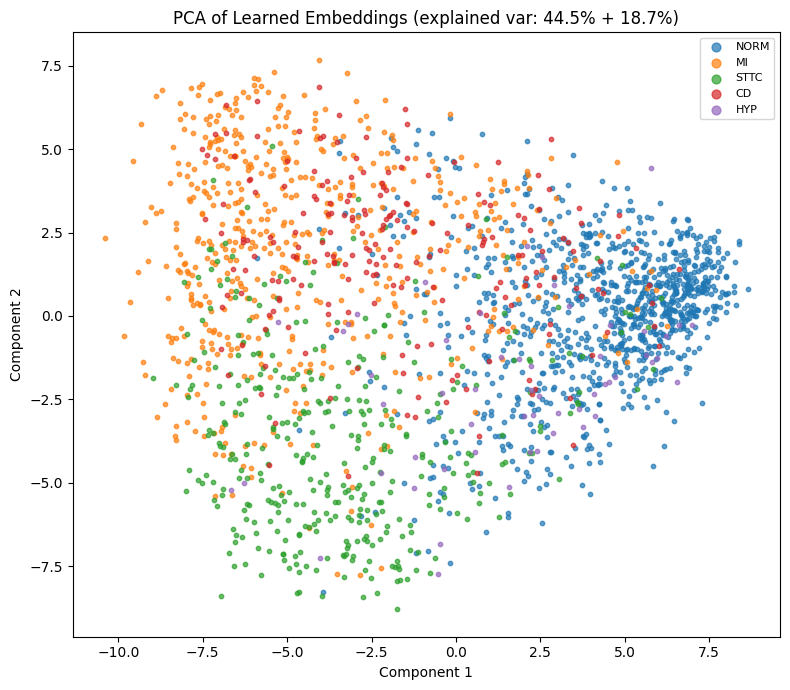

In [23]:
# Section 8.3 — PCA Projection
# ---------------------------------------------------------------------------

pca = PCA(n_components=2, random_state=EVAL_CONFIG.RANDOM_SEED)
pca_coords = pca.fit_transform(emb_sub)
explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 7))
scatter_by_class(ax, pca_coords, dominant_labels_sub,
                  f"PCA of Learned Embeddings (explained var: {explained[0]:.1%} + {explained[1]:.1%})")
plt.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.FIGURES_DIR, "pca.png"), dpi=300, bbox_inches="tight")
plt.show()

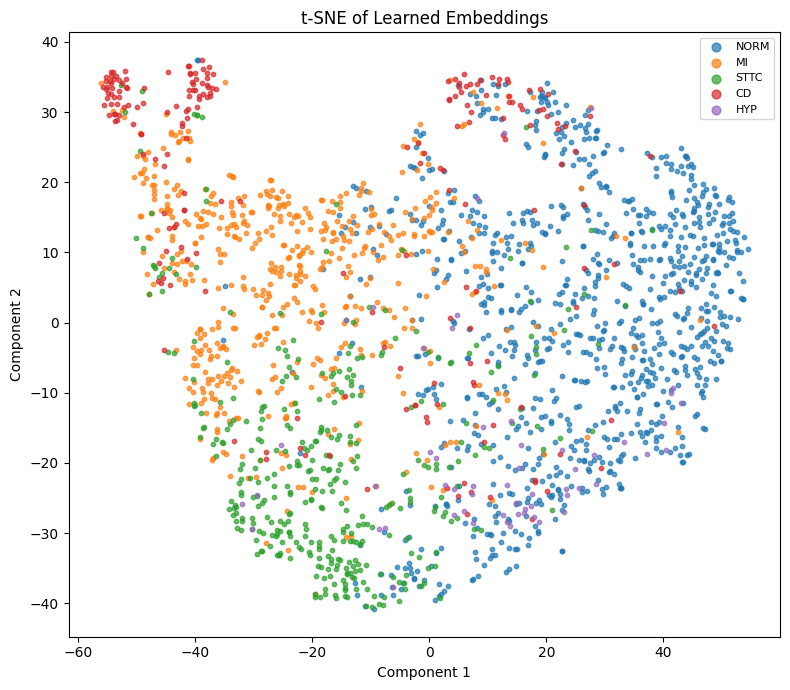

In [24]:
# Section 8.4 — t-SNE Projection
# ---------------------------------------------------------------------------

tsne = TSNE(n_components=2, perplexity=min(EVAL_CONFIG.TSNE_PERPLEXITY, max(5, len(emb_sub) // 4)),
            random_state=EVAL_CONFIG.RANDOM_SEED, init="pca", learning_rate="auto")
tsne_coords = tsne.fit_transform(emb_sub)

fig, ax = plt.subplots(figsize=(8, 7))
scatter_by_class(ax, tsne_coords, dominant_labels_sub, "t-SNE of Learned Embeddings")
plt.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.FIGURES_DIR, "tsne.png"), dpi=300, bbox_inches="tight")
plt.show()

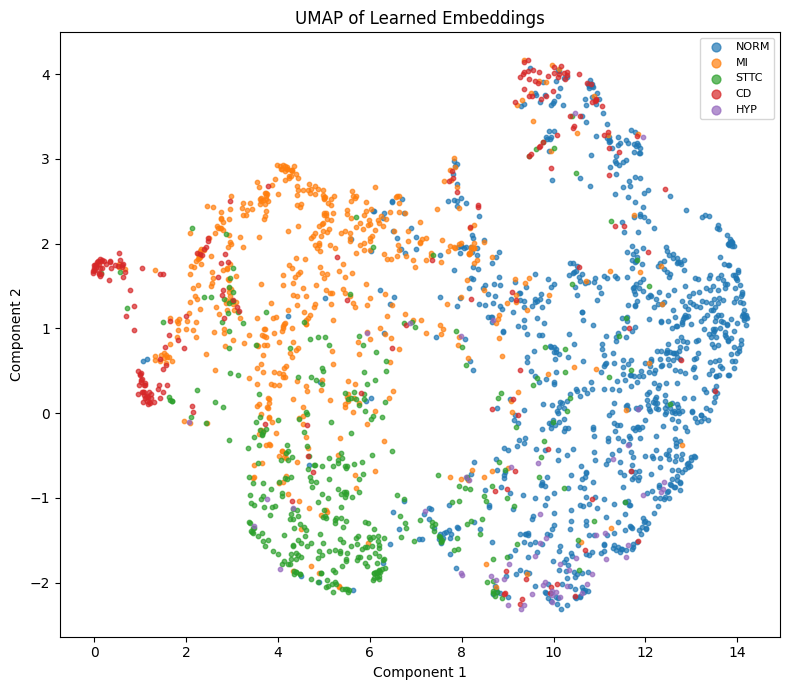

In [25]:
# Section 8.5 — UMAP Projection
# ---------------------------------------------------------------------------

umap_reducer = umap.UMAP(n_components=2, n_neighbors=min(EVAL_CONFIG.UMAP_N_NEIGHBORS, len(emb_sub) - 1),
                          min_dist=EVAL_CONFIG.UMAP_MIN_DIST, random_state=EVAL_CONFIG.RANDOM_SEED)
umap_coords = umap_reducer.fit_transform(emb_sub)

fig, ax = plt.subplots(figsize=(8, 7))
scatter_by_class(ax, umap_coords, dominant_labels_sub, "UMAP of Learned Embeddings")
plt.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.FIGURES_DIR, "umap.png"), dpi=300, bbox_inches="tight")
plt.show()

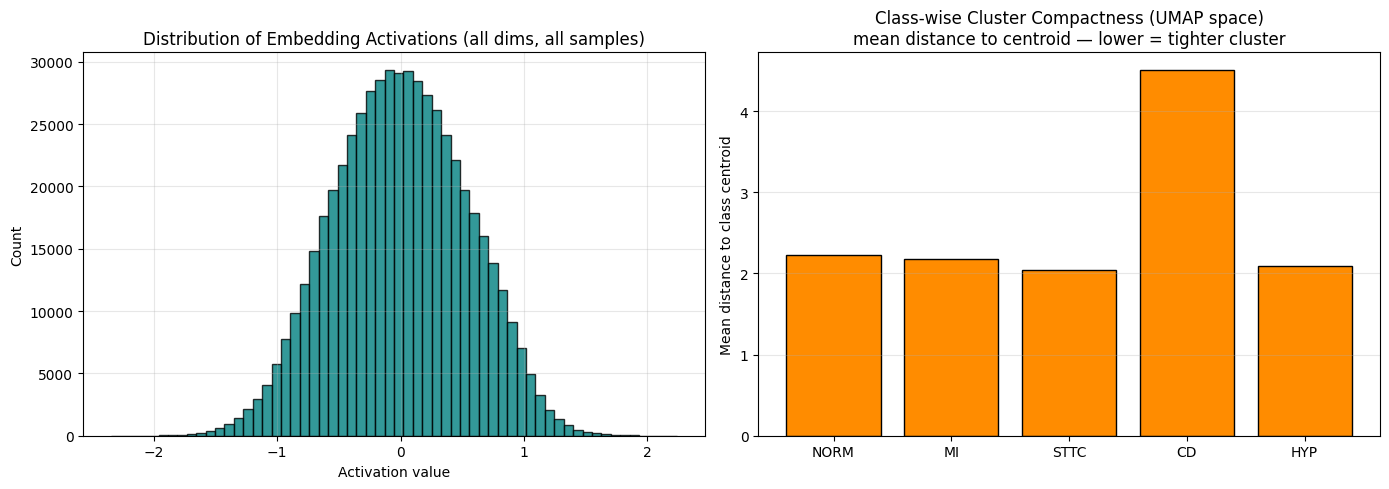

Class-wise cluster compactness (UMAP space, lower = tighter):
  STTC  : 2.038
  HYP   : 2.088
  MI    : 2.172
  NORM  : 2.223
  CD    : 4.501


In [26]:
# Section 8.6 — Embedding Distribution and Class-wise Cluster Compactness
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(embeddings.flatten(), bins=60, color="teal", edgecolor="black", alpha=0.8)
axes[0].set_title("Distribution of Embedding Activations (all dims, all samples)")
axes[0].set_xlabel("Activation value")
axes[0].set_ylabel("Count")
axes[0].grid(alpha=0.3)

# Class-wise cluster compactness in the UMAP space: mean intra-class pairwise centroid distance
# as a simple, interpretable proxy for how tightly each diagnostic superclass clusters.
compactness = {}
for c in CLASS_NAMES:
    mask = dominant_labels_sub == c
    if mask.sum() < 2:
        continue
    pts = umap_coords[mask]
    centroid = pts.mean(axis=0)
    compactness[c] = float(np.mean(np.linalg.norm(pts - centroid, axis=1)))

axes[1].bar(compactness.keys(), compactness.values(), color="darkorange", edgecolor="black")
axes[1].set_title("Class-wise Cluster Compactness (UMAP space)\nmean distance to centroid — lower = tighter cluster")
axes[1].set_ylabel("Mean distance to class centroid")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.FIGURES_DIR, "08_embedding_distribution_compactness.png"), dpi=300)
plt.show()

print("Class-wise cluster compactness (UMAP space, lower = tighter):")
for c, v in sorted(compactness.items(), key=lambda kv: kv[1]):
    print(f"  {c:6s}: {v:.3f}")

## Section 9 — Explainability

`ExplainabilityEngine` wraps `captum`'s Integrated Gradients and Saliency attribution methods
around the frozen model (input-gradient methods only — no weight updates). Per-sample,
per-lead-per-timestep attributions are aggregated into **lead importance** (which of the 12 leads
drives a prediction) and **temporal importance** (which part of the 10-second window drives it),
then overlaid on representative ECG waveforms for visual inspection.

In [27]:
# Section 9.1 — ExplainabilityEngine
# ---------------------------------------------------------------------------

class ExplainabilityEngine:
    """Computes Integrated Gradients / Saliency attributions for a frozen classifier.

    Parameters
    ----------
    model : nn.Module
        Frozen model returning `(batch, n_classes)` logits from `(batch, n_leads, length)` input.
    device : torch.device
    ig_steps : int
        Number of interpolation steps used by Integrated Gradients.
    """

    def __init__(self, model: nn.Module, device: torch.device, ig_steps: int = 50):
        self.model = model
        self.device = device
        self.ig_steps = ig_steps
        self._ig = IntegratedGradients(self.model)
        self._saliency = Saliency(self.model)

    def integrated_gradients(self, signal: torch.Tensor, target_class: int) -> np.ndarray:
        """Integrated Gradients attribution for one signal and target class.

        Parameters
        ----------
        signal : torch.Tensor
            Shape `(1, n_leads, length)`, on `self.device`.
        target_class : int
            Index into the model's output logits.

        Returns
        -------
        np.ndarray
            Shape `(n_leads, length)` attribution map.
        """
        signal = signal.clone().requires_grad_(True)
        baseline = torch.zeros_like(signal)
        attr = self._ig.attribute(signal, baselines=baseline, target=target_class,
                                   n_steps=self.ig_steps)
        return attr.detach().cpu().numpy()[0]

    def saliency_map(self, signal: torch.Tensor, target_class: int) -> np.ndarray:
        """Vanilla-gradient saliency map for one signal and target class.

        Parameters
        ----------
        signal : torch.Tensor
            Shape `(1, n_leads, length)`, on `self.device`.
        target_class : int

        Returns
        -------
        np.ndarray
            Shape `(n_leads, length)` attribution map.
        """
        signal = signal.clone().requires_grad_(True)
        attr = self._saliency.attribute(signal, target=target_class, abs=True)
        return attr.detach().cpu().numpy()[0]

    @staticmethod
    def lead_importance(attribution: np.ndarray) -> np.ndarray:
        """Aggregate an `(n_leads, length)` attribution map into per-lead importance `(n_leads,)`."""
        return np.mean(np.abs(attribution), axis=1)

    @staticmethod
    def temporal_importance(attribution: np.ndarray) -> np.ndarray:
        """Aggregate an `(n_leads, length)` attribution map into per-timestep importance `(length,)`."""
        return np.mean(np.abs(attribution), axis=0)


explain_engine = ExplainabilityEngine(model, EVAL_CONFIG.DEVICE, EVAL_CONFIG.IG_STEPS)
print("ExplainabilityEngine ready (Integrated Gradients + Saliency).")

ExplainabilityEngine ready (Integrated Gradients + Saliency).


In [28]:
# Section 9.2 — Select Representative ECGs (one confident true positive per class)
# ---------------------------------------------------------------------------

def select_representative_indices(results: InferenceResults, class_names: List[str], n_per_class: int = 1
                                    ) -> Dict[str, List[int]]:
    """Pick the most confident true-positive test-set indices for each class.

    Parameters
    ----------
    results : InferenceResults
    class_names : list[str]
    n_per_class : int
        How many representative indices to select per class.

    Returns
    -------
    dict[str, list[int]]
        Class name -> list of row indices into `results.*` arrays.
    """
    picks = {}
    for j, cls in enumerate(class_names):
        true_positive = (results.labels[:, j] == 1) & (results.preds[:, j] == 1)
        candidate_idx = np.where(true_positive)[0]
        if len(candidate_idx) == 0:
            picks[cls] = []
            continue
        ordered = candidate_idx[np.argsort(-results.probs[candidate_idx, j])]
        picks[cls] = ordered[:n_per_class].tolist()
    return picks


representative_indices = select_representative_indices(
    results, CLASS_NAMES, n_per_class=max(1, EVAL_CONFIG.N_EXPLAIN_SAMPLES // len(CLASS_NAMES))
)
for cls, idxs in representative_indices.items():
    print(f"{cls:6s}: {len(idxs)} representative sample(s) selected "
          f"(ecg_id={[int(results.ecg_ids[i]) for i in idxs]})")

NORM  : 1 representative sample(s) selected (ecg_id=[2432])
MI    : 1 representative sample(s) selected (ecg_id=[6552])
STTC  : 1 representative sample(s) selected (ecg_id=[12649])
CD    : 1 representative sample(s) selected (ecg_id=[18777])
HYP   : 1 representative sample(s) selected (ecg_id=[9869])


In [29]:
# Section 9.3 — Fetch Raw Signals for Explainability by ecg_id
# ---------------------------------------------------------------------------

def fetch_signal_by_ecg_id(dataset, ecg_id: int) -> torch.Tensor:
    """Retrieve the exact preprocessed `(n_leads, length)` tensor the model saw for `ecg_id`."""
    pos = dataset.ecg_ids.index(int(ecg_id))
    signal, _, _ = dataset[pos]
    return signal


test_dataset = test_loader.dataset
_t_axis = np.arange(CONFIG.SIGNAL_LENGTH) / CONFIG.SAMPLING_RATE
print(f"Test dataset ready for on-demand signal lookup ({len(test_dataset)} records).")

Test dataset ready for on-demand signal lookup (2163 records).


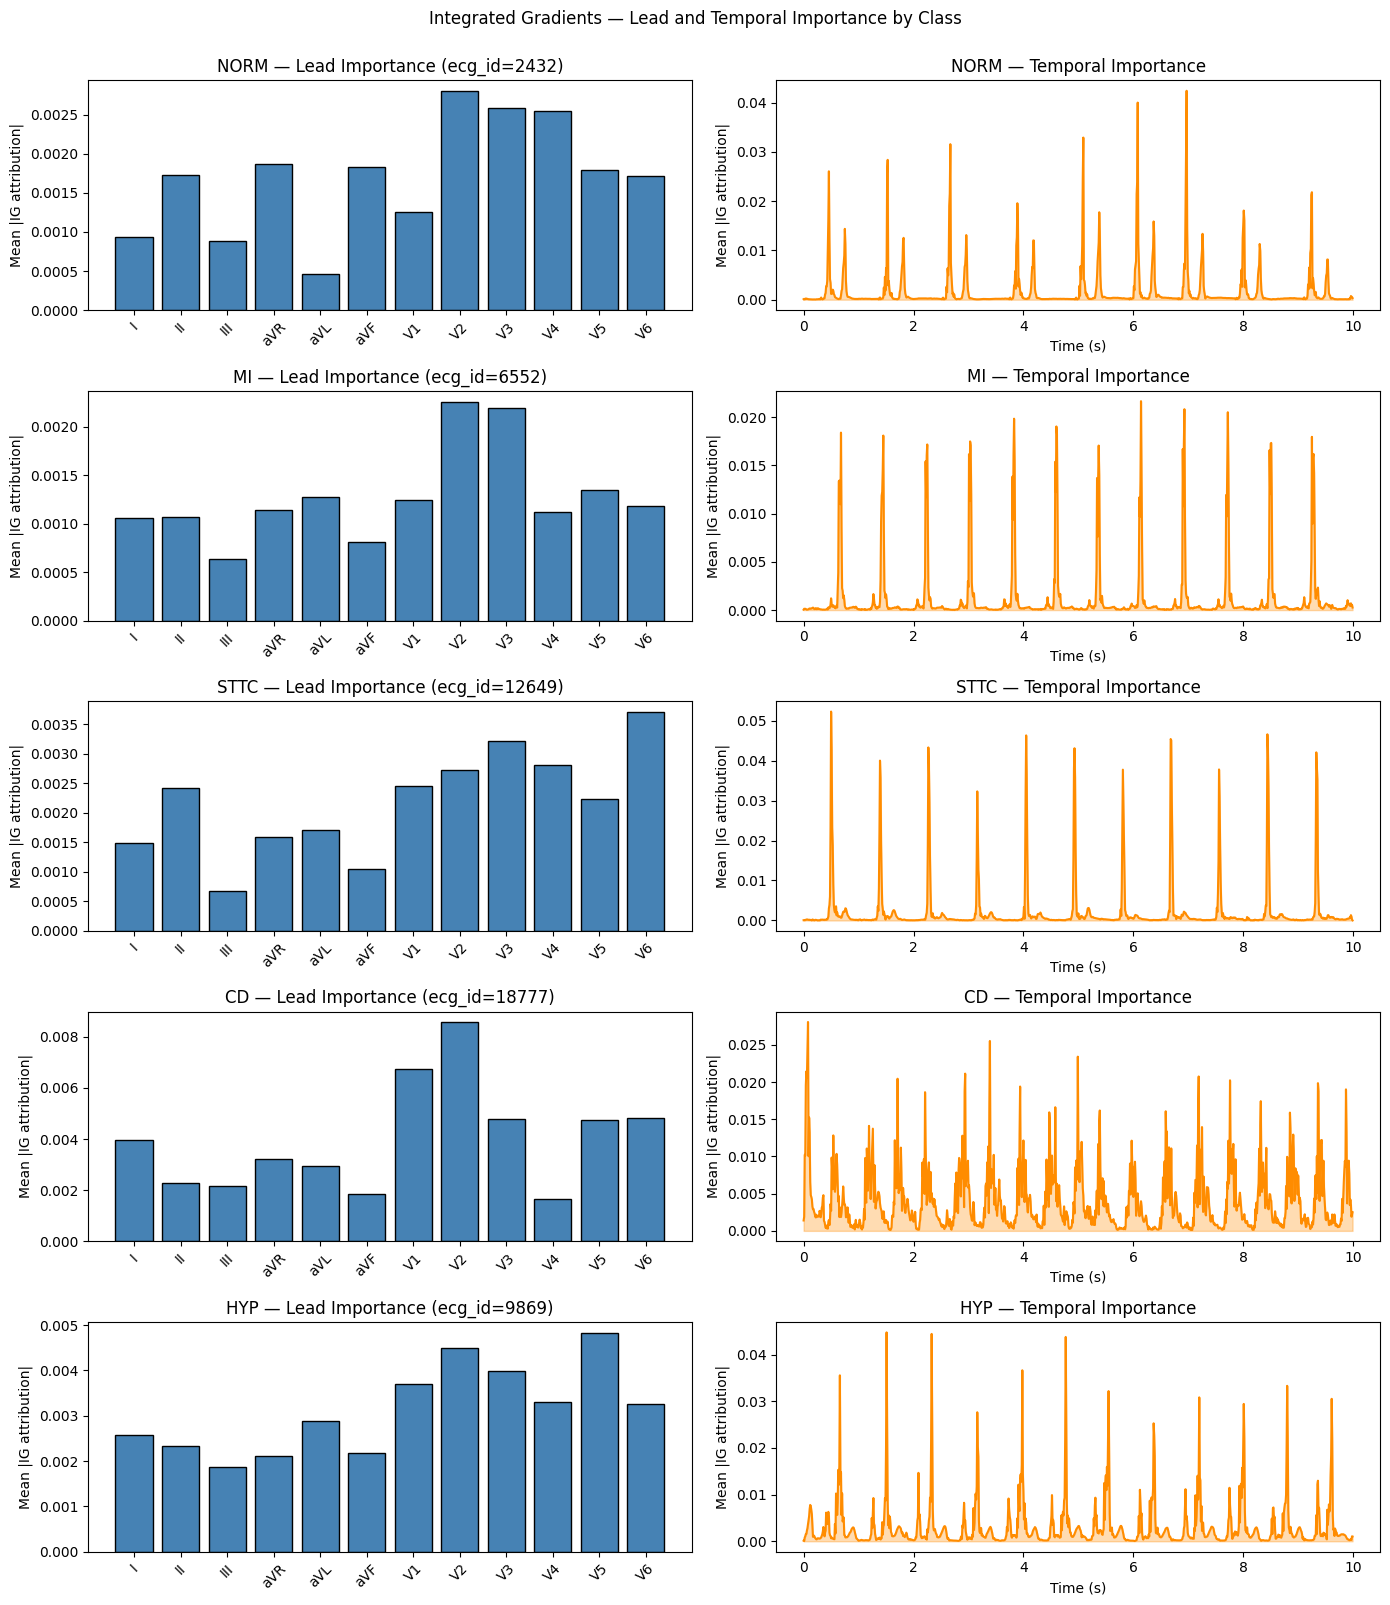

In [30]:
# Section 9.4 — Integrated Gradients: Lead & Temporal Importance
# ---------------------------------------------------------------------------

ig_records = []  # (class, ecg_id, attribution (n_leads, length))
for j, cls in enumerate(CLASS_NAMES):
    for idx in representative_indices[cls]:
        ecg_id = int(results.ecg_ids[idx])
        signal = fetch_signal_by_ecg_id(test_dataset, ecg_id).unsqueeze(0).to(EVAL_CONFIG.DEVICE)
        attr = explain_engine.integrated_gradients(signal, target_class=j)
        ig_records.append({"class": cls, "ecg_id": ecg_id, "attribution": attr})

fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(14, 3.2 * len(CLASS_NAMES)))
for row, cls in enumerate(CLASS_NAMES):
    matching = [r for r in ig_records if r["class"] == cls]
    if not matching:
        axes[row, 0].axis("off"); axes[row, 1].axis("off")
        continue
    attr = matching[0]["attribution"]
    lead_imp = explain_engine.lead_importance(attr)
    temporal_imp = explain_engine.temporal_importance(attr)

    axes[row, 0].bar(CONFIG.LEAD_NAMES, lead_imp, color="steelblue", edgecolor="black")
    axes[row, 0].set_title(f"{cls} — Lead Importance (ecg_id={matching[0]['ecg_id']})")
    axes[row, 0].set_ylabel("Mean |IG attribution|")
    axes[row, 0].tick_params(axis="x", rotation=45)

    axes[row, 1].plot(_t_axis, temporal_imp, color="darkorange")
    axes[row, 1].fill_between(_t_axis, temporal_imp, color="darkorange", alpha=0.3)
    axes[row, 1].set_title(f"{cls} — Temporal Importance")
    axes[row, 1].set_xlabel("Time (s)")
    axes[row, 1].set_ylabel("Mean |IG attribution|")

fig.suptitle("Integrated Gradients — Lead and Temporal Importance by Class", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.EXPLAINABILITY_DIR, "integrated_gradients.png"), dpi=300, bbox_inches="tight")
plt.show()

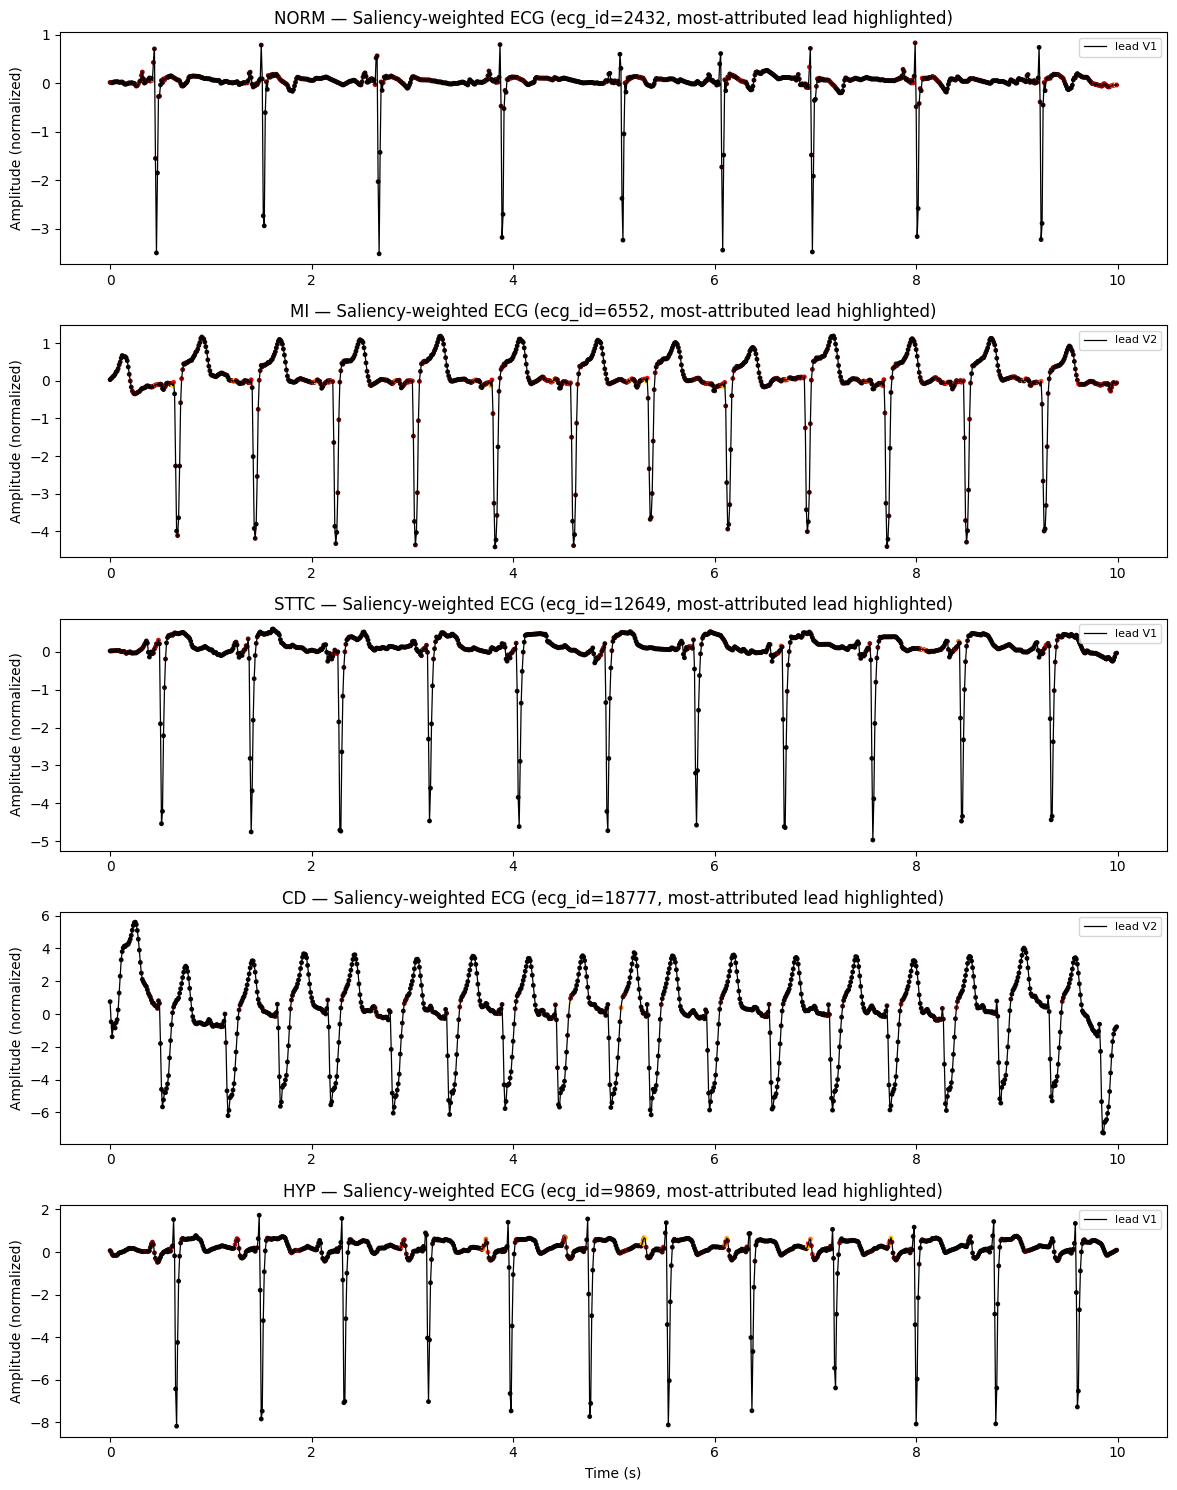

In [31]:
# Section 9.5 — Saliency Maps on Representative ECG Waveforms
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(len(CLASS_NAMES), 1, figsize=(12, 3.0 * len(CLASS_NAMES)))
axes = np.atleast_1d(axes)
for row, cls in enumerate(CLASS_NAMES):
    idxs = representative_indices[cls]
    ax = axes[row]
    if not idxs:
        ax.axis("off")
        continue
    j = CLASS_NAMES.index(cls)
    idx = idxs[0]
    ecg_id = int(results.ecg_ids[idx])
    signal_t = fetch_signal_by_ecg_id(test_dataset, ecg_id)
    signal = signal_t.unsqueeze(0).to(EVAL_CONFIG.DEVICE)
    sal = explain_engine.saliency_map(signal, target_class=j)
    lead_energy = np.mean(np.abs(sal), axis=1)
    top_lead = int(np.argmax(lead_energy))

    raw = signal_t.numpy()[top_lead]
    sal_lead = sal[top_lead]
    sal_norm = (sal_lead - sal_lead.min()) / (sal_lead.max() - sal_lead.min() + 1e-8)

    ax.plot(_t_axis, raw, color="black", lw=0.9, label=f"lead {CONFIG.LEAD_NAMES[top_lead]}")
    sc = ax.scatter(_t_axis, raw, c=sal_norm, cmap="hot", s=6)
    ax.set_title(f"{cls} — Saliency-weighted ECG (ecg_id={ecg_id}, most-attributed lead highlighted)")
    ax.set_ylabel("Amplitude (normalized)")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.EXPLAINABILITY_DIR, "saliency_maps.png"), dpi=300, bbox_inches="tight")
plt.show()

## Section 10 — Error Analysis

`ErrorAnalyzer` catalogs *where* the model is wrong, not just *how often*: per-class false
positives/negatives, high-confidence errors (the most concerning failure mode — confidently
wrong), low-confidence predictions near the decision boundary, and errors specifically on the
rarest diagnostic superclass in the test fold, where limited positive examples make
generalization hardest.

In [32]:
# Section 10.1 — ErrorAnalyzer
# ---------------------------------------------------------------------------

class ErrorAnalyzer:
    """Catalogs classification errors by category for a completed inference pass.

    Parameters
    ----------
    class_names : list[str]
    high_confidence_threshold : float
        Confidence (see `InferenceResults.confidences`) above which an error is "high confidence".
    low_confidence_band : float
        |p - 0.5| below which a per-class prediction counts as "low confidence".
    """

    def __init__(self, class_names: List[str], high_confidence_threshold: float = 0.85,
                 low_confidence_band: float = 0.10):
        self.class_names = class_names
        self.high_confidence_threshold = high_confidence_threshold
        self.low_confidence_band = low_confidence_band

    def false_positives(self, results: InferenceResults, class_idx: int) -> np.ndarray:
        """Row indices where `class_idx` was predicted positive but is truly negative."""
        return np.where((results.preds[:, class_idx] == 1) & (results.labels[:, class_idx] == 0))[0]

    def false_negatives(self, results: InferenceResults, class_idx: int) -> np.ndarray:
        """Row indices where `class_idx` was predicted negative but is truly positive."""
        return np.where((results.preds[:, class_idx] == 0) & (results.labels[:, class_idx] == 1))[0]

    def high_confidence_errors(self, results: InferenceResults) -> np.ndarray:
        """Row indices with >=1 misclassified class AND overall confidence above threshold."""
        any_error = (results.preds != results.labels).any(axis=1)
        return np.where(any_error & (results.confidences >= self.high_confidence_threshold))[0]

    def low_confidence_predictions(self, results: InferenceResults, class_idx: int) -> np.ndarray:
        """Row indices where `class_idx`'s probability sits within `low_confidence_band` of 0.5."""
        return np.where(np.abs(results.probs[:, class_idx] - 0.5) <= self.low_confidence_band)[0]

    def rare_class_errors(self, results: InferenceResults) -> Tuple[str, np.ndarray]:
        """Errors restricted to the least-prevalent class (by test-set positive count)."""
        positive_counts = results.labels.sum(axis=0)
        rare_idx = int(np.argmin(positive_counts))
        rare_cls = self.class_names[rare_idx]
        errors = np.where(results.preds[:, rare_idx] != results.labels[:, rare_idx])[0]
        return rare_cls, errors

    def summary_table(self, results: InferenceResults) -> pd.DataFrame:
        """One row per class: FP count, FN count, and low-confidence-prediction count."""
        rows = []
        for j, cls in enumerate(self.class_names):
            rows.append({
                "class": cls,
                "false_positives": len(self.false_positives(results, j)),
                "false_negatives": len(self.false_negatives(results, j)),
                "low_confidence_predictions": len(self.low_confidence_predictions(results, j)),
            })
        return pd.DataFrame(rows)


error_analyzer = ErrorAnalyzer(CLASS_NAMES, EVAL_CONFIG.HIGH_CONFIDENCE_THRESHOLD,
                                EVAL_CONFIG.LOW_CONFIDENCE_BAND)
error_summary = error_analyzer.summary_table(results)
high_conf_errors = error_analyzer.high_confidence_errors(results)
rare_class, rare_class_errors = error_analyzer.rare_class_errors(results)

print("Per-class error summary:")
print(error_summary.to_string(index=False))
print(f"\nHigh-confidence errors (confidence >= {EVAL_CONFIG.HIGH_CONFIDENCE_THRESHOLD}): "
      f"{len(high_conf_errors)} / {len(results.ecg_ids)} records")
print(f"Rarest test-fold class: {rare_class} "
      f"({int(results.labels[:, CLASS_NAMES.index(rare_class)].sum())} positives) "
      f"-> {len(rare_class_errors)} misclassifications")

Per-class error summary:
class  false_positives  false_negatives  low_confidence_predictions
 NORM              201               91                         106
   MI              152              124                         134
 STTC              153               93                         134
   CD               57              165                         135
  HYP              142              123                         280

High-confidence errors (confidence >= 0.85): 43 / 2163 records
Rarest test-fold class: HYP (263 positives) -> 265 misclassifications


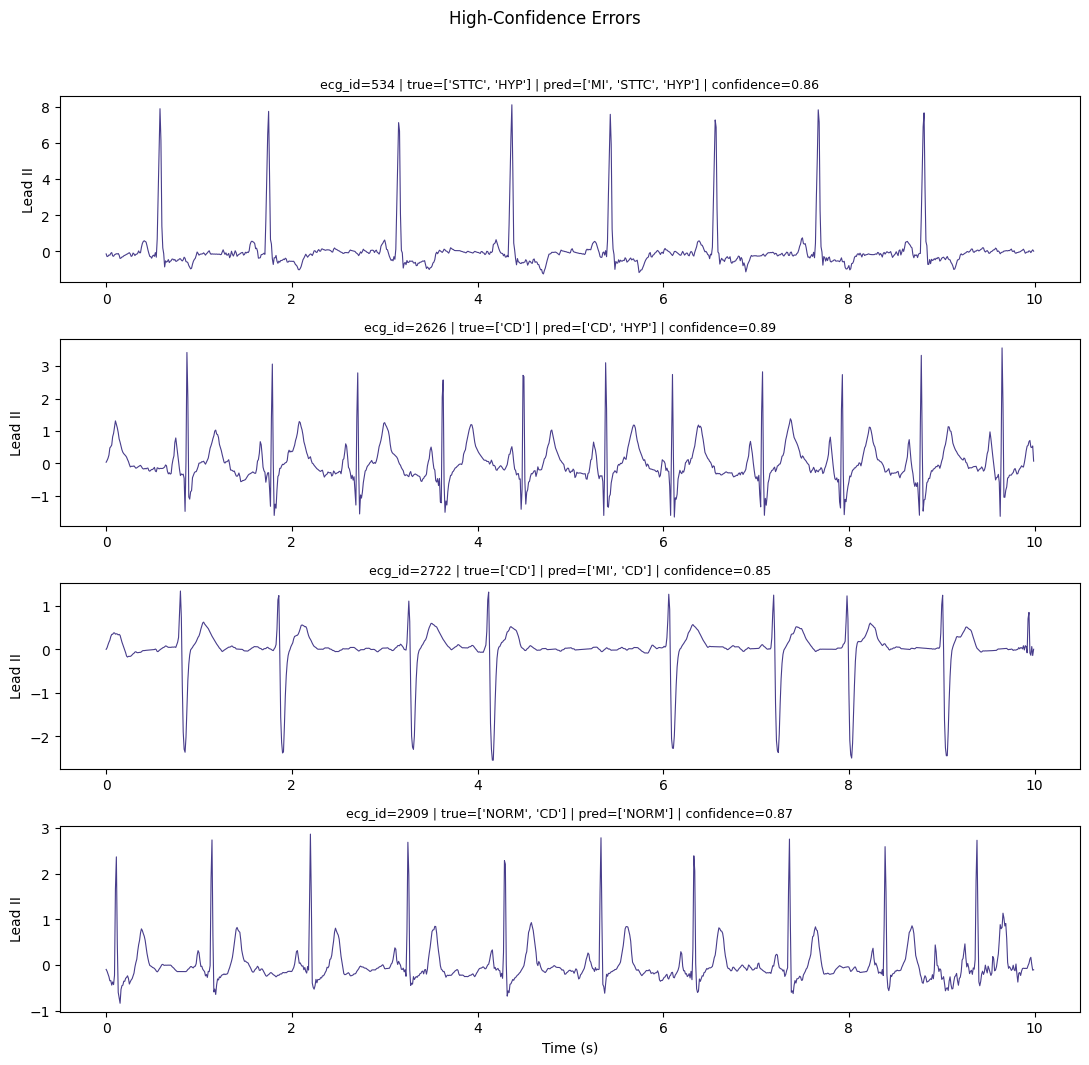

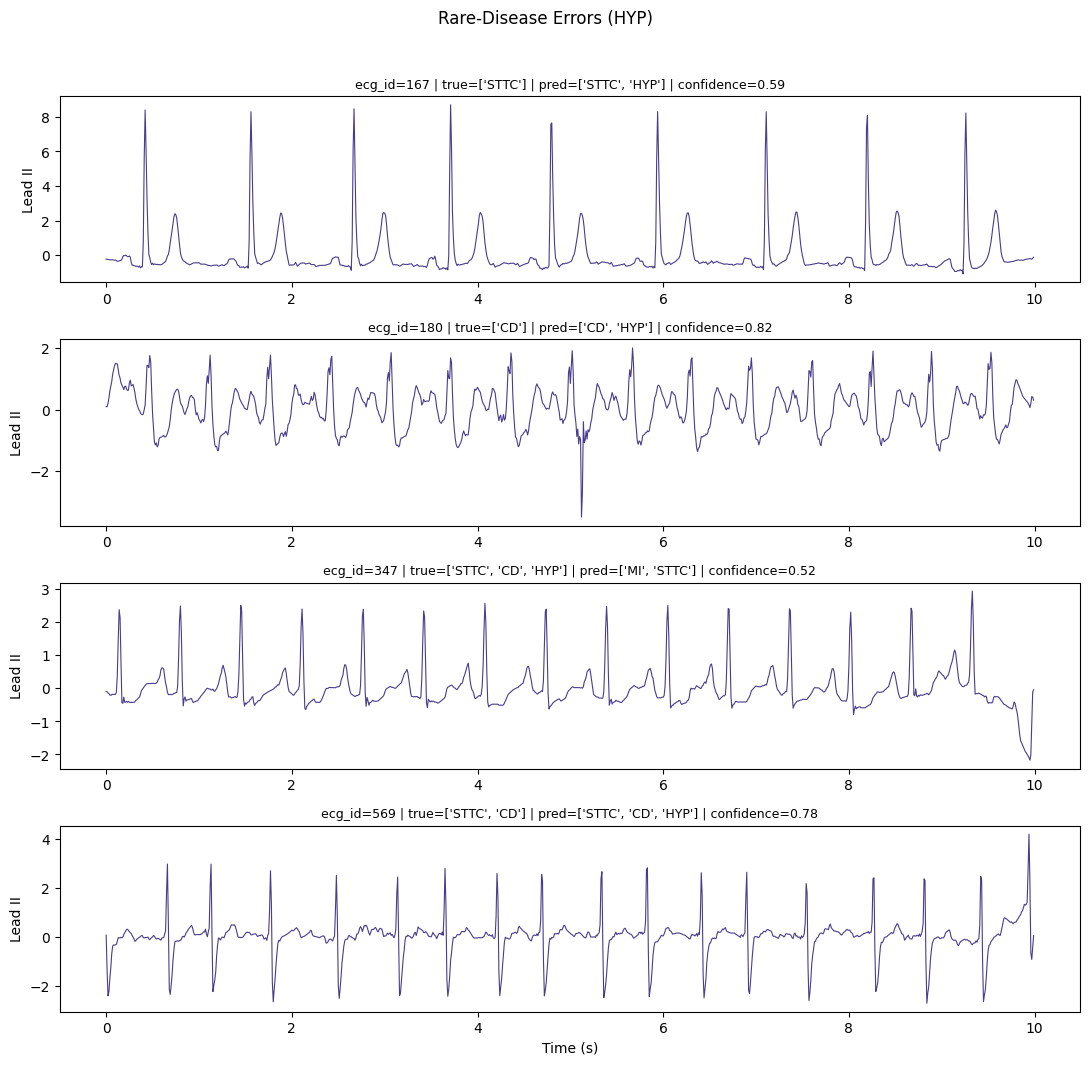

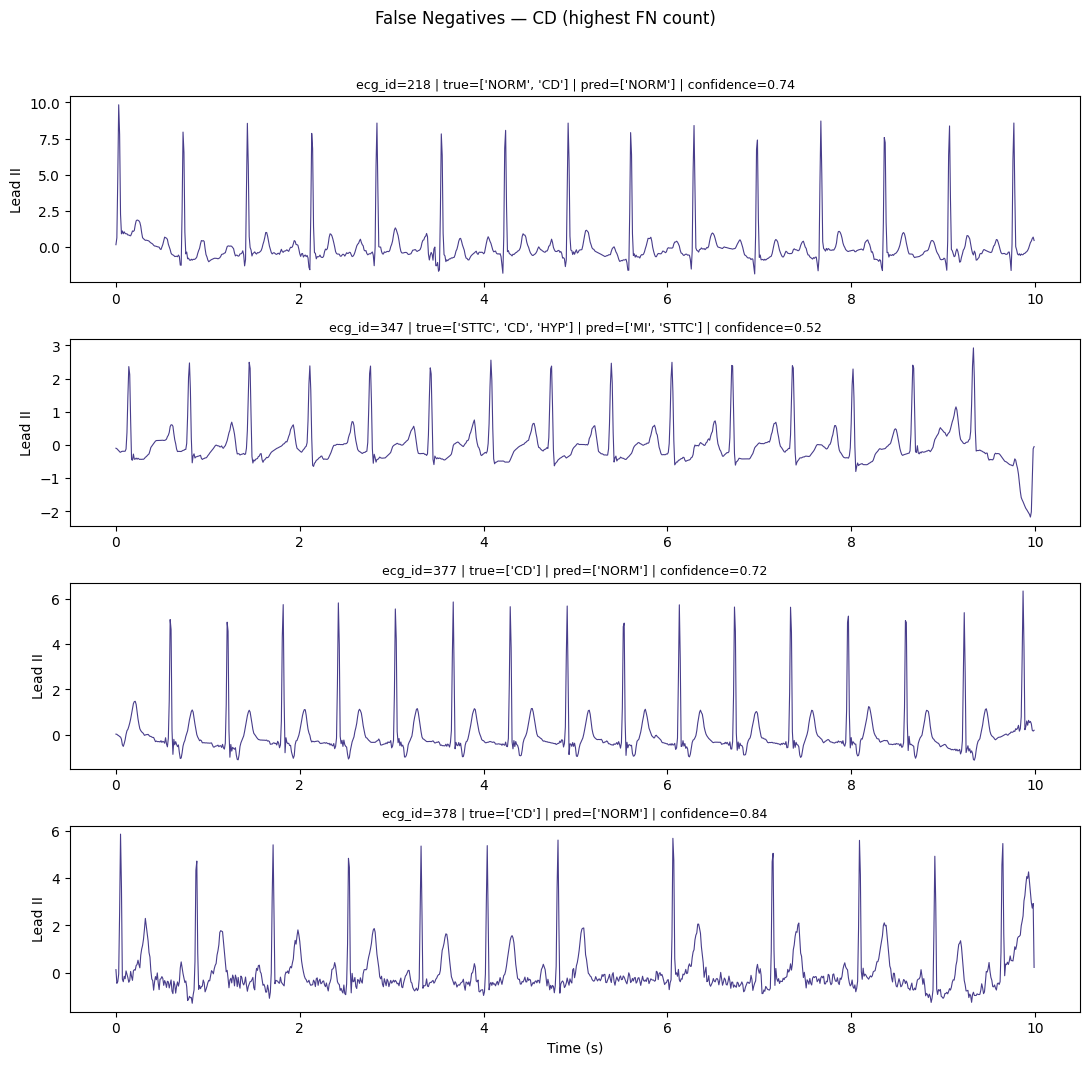

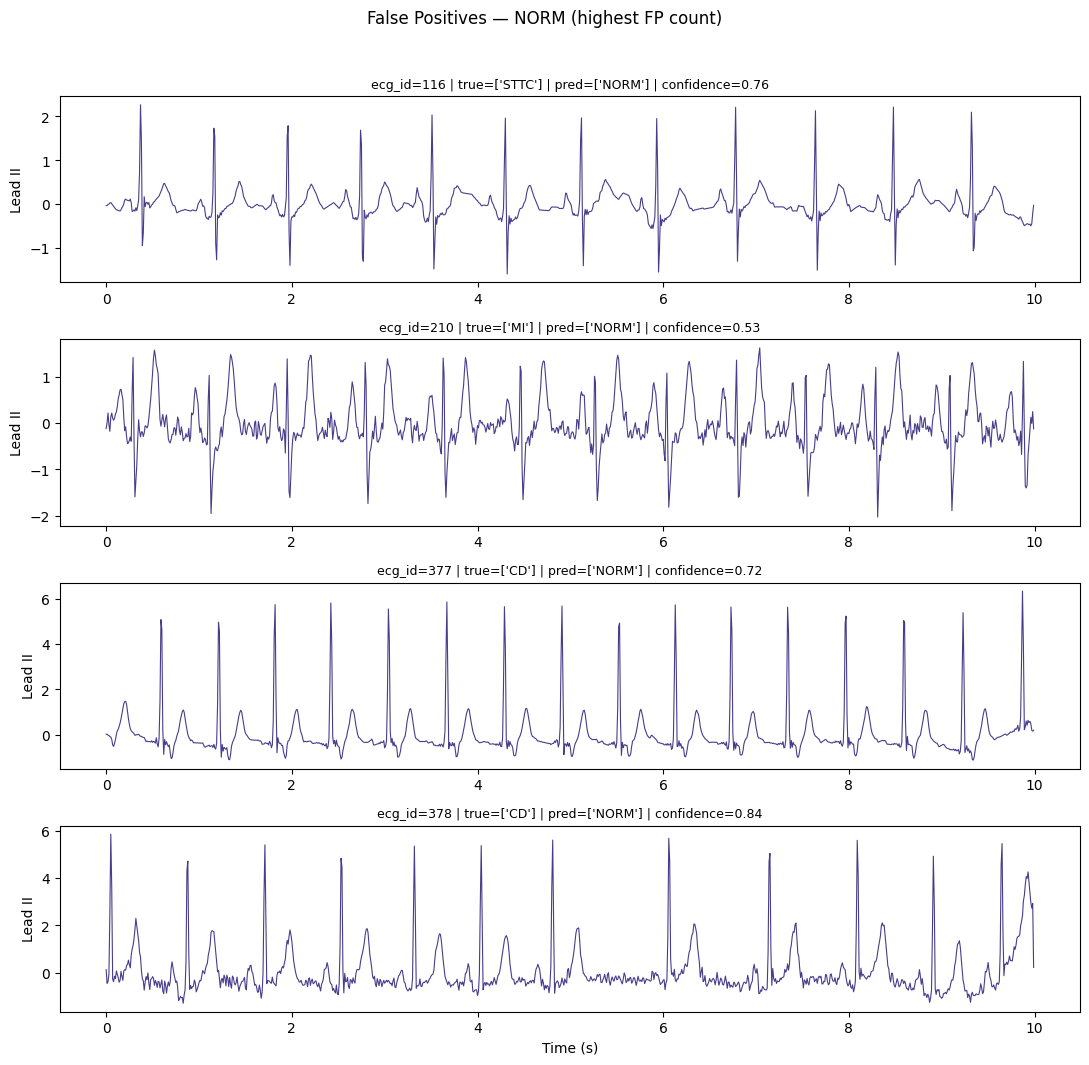

In [33]:
# Section 10.2 — Display Representative Error ECGs
# ---------------------------------------------------------------------------

def plot_error_examples(indices: np.ndarray, title: str, filename: str,
                         max_examples: int = EVAL_CONFIG.N_ERROR_EXAMPLES) -> None:
    """Plot lead-II waveforms for up to `max_examples` error cases with true/pred label overlays."""
    indices = indices[:max_examples]
    if len(indices) == 0:
        print(f"[skip] No examples for: {title}")
        return
    fig, axes = plt.subplots(len(indices), 1, figsize=(11, 2.6 * len(indices)))
    axes = np.atleast_1d(axes)
    lead_ii = CONFIG.LEAD_NAMES.index("II")
    for ax, idx in zip(axes, indices):
        ecg_id = int(results.ecg_ids[idx])
        signal = fetch_signal_by_ecg_id(test_dataset, ecg_id).numpy()
        true_cls = [CLASS_NAMES[j] for j in range(len(CLASS_NAMES)) if results.labels[idx, j] == 1] or ["NONE"]
        pred_cls = [CLASS_NAMES[j] for j in range(len(CLASS_NAMES)) if results.preds[idx, j] == 1] or ["NONE"]
        ax.plot(_t_axis, signal[lead_ii], color="darkslateblue", lw=0.8)
        ax.set_title(f"ecg_id={ecg_id} | true={true_cls} | pred={pred_cls} | "
                     f"confidence={results.confidences[idx]:.2f}", fontsize=9)
        ax.set_ylabel("Lead II")
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    fig.savefig(os.path.join(EVAL_CONFIG.EXPLAINABILITY_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


plot_error_examples(high_conf_errors, "High-Confidence Errors", "10_high_confidence_errors.png")
plot_error_examples(rare_class_errors, f"Rare-Disease Errors ({rare_class})", "10_rare_disease_errors.png")

_worst_class_idx = int(error_summary["false_negatives"].idxmax())
_worst_class = error_summary.loc[_worst_class_idx, "class"]
_worst_fn = error_analyzer.false_negatives(results, CLASS_NAMES.index(_worst_class))
plot_error_examples(_worst_fn, f"False Negatives — {_worst_class} (highest FN count)", "10_false_negatives.png")

_worst_fp_idx = int(error_summary["false_positives"].idxmax())
_worst_fp_class = error_summary.loc[_worst_fp_idx, "class"]
_worst_fp = error_analyzer.false_positives(results, CLASS_NAMES.index(_worst_fp_class))
plot_error_examples(_worst_fp, f"False Positives — {_worst_fp_class} (highest FP count)", "10_false_positives.png")

## Section 11 — Computational Analysis

Measures deployment-relevant cost: parameter count, on-disk size, single-sample latency,
throughput, peak GPU memory, and an estimated FLOP count. `mamba_ssm`'s selective-scan CUDA
kernel is a custom op most static FLOP profilers (`thop`, `fvcore`) do not know how to count, so
the FLOP figure below is reported as an **explicit estimate** with its formula shown, not a
profiler-verified exact count.

In [34]:
# Section 11.1 — Parameters, Size, Latency, Throughput, Memory
# ---------------------------------------------------------------------------

class ComputationalProfiler:
    """Measures deployment-relevant cost metrics for a frozen model.

    Parameters
    ----------
    model : nn.Module
    device : torch.device
    """

    def __init__(self, model: nn.Module, device: torch.device):
        self.model = model.eval()
        self.device = device

    def parameter_stats(self) -> Dict[str, float]:
        """Total parameters and on-disk `state_dict` size in MB."""
        n_params = sum(p.numel() for p in self.model.parameters())
        size_mb = sum(p.numel() * p.element_size() for p in self.model.state_dict().values()) / (1024 ** 2)
        return {"total_parameters": n_params, "model_size_mb": size_mb}

    @torch.no_grad()
    def latency_throughput(self, signal_shape: Tuple[int, int], batch_size: int = 1,
                            n_warmup: int = 10, n_runs: int = 50) -> Dict[str, float]:
        """Single-sample latency (ms) and throughput (samples/sec) via repeated timed forward passes.

        Parameters
        ----------
        signal_shape : tuple[int, int]
            `(n_leads, length)`.
        batch_size : int
        n_warmup, n_runs : int
            Untimed warmup iterations, then timed iterations.
        """
        dummy = torch.randn(batch_size, *signal_shape, device=self.device)
        for _ in range(n_warmup):
            self.model(dummy)
        if self.device.type == "cuda":
            torch.cuda.synchronize()

        timings = []
        for _ in range(n_runs):
            start = time.perf_counter()
            self.model(dummy)
            if self.device.type == "cuda":
                torch.cuda.synchronize()
            timings.append(time.perf_counter() - start)

        timings = np.array(timings)
        mean_latency_ms = float(timings.mean() * 1000)
        return {
            "mean_latency_ms": mean_latency_ms,
            "p50_latency_ms": float(np.percentile(timings, 50) * 1000),
            "p95_latency_ms": float(np.percentile(timings, 95) * 1000),
            "throughput_samples_per_sec": float(batch_size / timings.mean()),
        }

    @torch.no_grad()
    def gpu_memory_mb(self, signal_shape: Tuple[int, int], batch_size: int) -> Optional[float]:
        """Peak GPU memory (MB) allocated during one forward pass, or None on CPU."""
        if self.device.type != "cuda":
            return None
        torch.cuda.reset_peak_memory_stats(self.device)
        dummy = torch.randn(batch_size, *signal_shape, device=self.device)
        self.model(dummy)
        torch.cuda.synchronize()
        return torch.cuda.max_memory_allocated(self.device) / (1024 ** 2)

    def estimate_flops(self, embed_dim: int, n_layers: int, d_state: int, d_conv: int,
                        expand: int, n_leads: int, n_classes: int, hidden_dim: int,
                        seq_len: int) -> Dict[str, float]:
        """Approximate forward-pass FLOPs (multiply-adds counted as 2 FLOPs).

        This is a **hand-derived estimate**, not a profiler-verified count: `mamba_ssm`'s fused
        selective-scan kernel has no public per-op FLOP breakdown. The selective-scan term below
        follows the standard SSM FLOP approximation used in the Mamba paper (linear in sequence
        length and state size), the same convention used for Notebooks 03/04's non-selective
        baselines where applicable.

        Returns
        -------
        dict[str, float]
            `{"estimated_flops": ..., "estimated_gflops": ...}`.
        """
        d_inner = expand * embed_dim
        input_proj_flops = 2 * seq_len * n_leads * embed_dim
        per_layer_flops = (
            2 * seq_len * embed_dim * d_inner * 2          # in/out linear projections
            + 2 * seq_len * d_inner * d_conv                # causal depthwise conv
            + 2 * seq_len * d_inner * d_state * 2            # selective-scan (state update + output), approx.
        )
        backbone_flops = n_layers * per_layer_flops
        head_flops = 2 * embed_dim * hidden_dim + 2 * hidden_dim * n_classes
        total = input_proj_flops + backbone_flops + head_flops
        return {"estimated_flops": float(total), "estimated_gflops": float(total / 1e9)}


profiler = ComputationalProfiler(model, EVAL_CONFIG.DEVICE)
param_stats = profiler.parameter_stats()
latency_stats = profiler.latency_throughput(
    (CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH),
    batch_size=EVAL_CONFIG.LATENCY_BATCH_SIZE,
    n_warmup=EVAL_CONFIG.N_WARMUP_RUNS, n_runs=EVAL_CONFIG.N_LATENCY_RUNS,
)
memory_mb = profiler.gpu_memory_mb((CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH), batch_size=EVAL_CONFIG.BATCH_SIZE)
flop_stats = profiler.estimate_flops(
    embed_dim=TRAINED_CONFIG["EMBED_DIM"], n_layers=TRAINED_CONFIG["N_MAMBA_LAYERS"],
    d_state=TRAINED_CONFIG["D_STATE"], d_conv=TRAINED_CONFIG["D_CONV"], expand=TRAINED_CONFIG["EXPAND"],
    n_leads=CONFIG.N_LEADS, n_classes=CONFIG.N_CLASSES, hidden_dim=TRAINED_CONFIG["HIDDEN_DIM"],
    seq_len=CONFIG.SIGNAL_LENGTH,
)

complexity_analysis = {**param_stats, **latency_stats, "gpu_memory_mb_at_eval_batch_size": memory_mb,
                        **flop_stats, "eval_batch_size": EVAL_CONFIG.BATCH_SIZE}

print("Computational profile:")
for k, v in complexity_analysis.items():
    print(f"  {k:36s}: {v}")

Computational profile:
  total_parameters                    : 1673990
  model_size_mb                       : 6.385765075683594
  mean_latency_ms                     : 9.963447980001092
  p50_latency_ms                      : 9.857367000051909
  p95_latency_ms                      : 10.717196050057964
  throughput_samples_per_sec          : 100.3668611516041
  gpu_memory_mb_at_eval_batch_size    : 1092.6650390625
  estimated_flops                     : 900164096.0
  estimated_gflops                    : 0.900164096
  eval_batch_size                     : 128


In [35]:
# Section 11.2 — Export Complexity Analysis
# ---------------------------------------------------------------------------

complexity_df = pd.DataFrame([complexity_analysis])
complexity_path = os.path.join(EVAL_CONFIG.TABLES_DIR, "complexity_analysis.csv")
complexity_df.to_csv(complexity_path, index=False)
print(f"Saved complexity analysis -> {complexity_path}")
complexity_df.T.rename(columns={0: "value"})

Saved complexity analysis -> ./mamba_evaluation_outputs/tables/complexity_analysis.csv


,value
total_parameters,1.673990e+06
model_size_mb,6.385765e+00
mean_latency_ms,9.963448e+00
p50_latency_ms,9.857367e+00
p95_latency_ms,1.071720e+01
throughput_samples_per_sec,1.003669e+02
gpu_memory_mb_at_eval_batch_size,1.092665e+03
estimated_flops,9.001641e+08
estimated_gflops,9.001641e-01
eval_batch_size,1.280000e+02


## Section 12 — Training History

Reloads Notebook 05's `training_history.csv` (already located in Section 2.4) — no retraining
occurs here — to display the loss/AUROC/learning-rate trajectory actually followed during
training, alongside this notebook's independently-measured test-set performance for context.

In [36]:
# Section 12.1 — Load and Plot Training Curves
# ---------------------------------------------------------------------------

training_history_df = pd.read_csv(os.path.join(CHECKPOINT_DIR, "training_history.csv"))
print(f"Loaded training_history.csv: {len(training_history_df)} epochs.")
training_history_df.tail()

Loaded training_history.csv: 16 epochs.


,epoch,train_loss,val_loss,train_auroc,val_auroc,learning_rate,epoch_time_sec
11,12,0.596422,0.536061,0.941584,0.925761,0.000274,130.419545
12,13,0.588923,0.541263,0.944124,0.923898,0.000268,130.289197
13,14,0.581292,0.572472,0.946672,0.919202,0.000261,130.125555
14,15,0.575504,0.533759,0.948820,0.926536,0.000254,130.462902
15,16,0.566803,0.536887,0.951461,0.925660,0.000247,130.070667


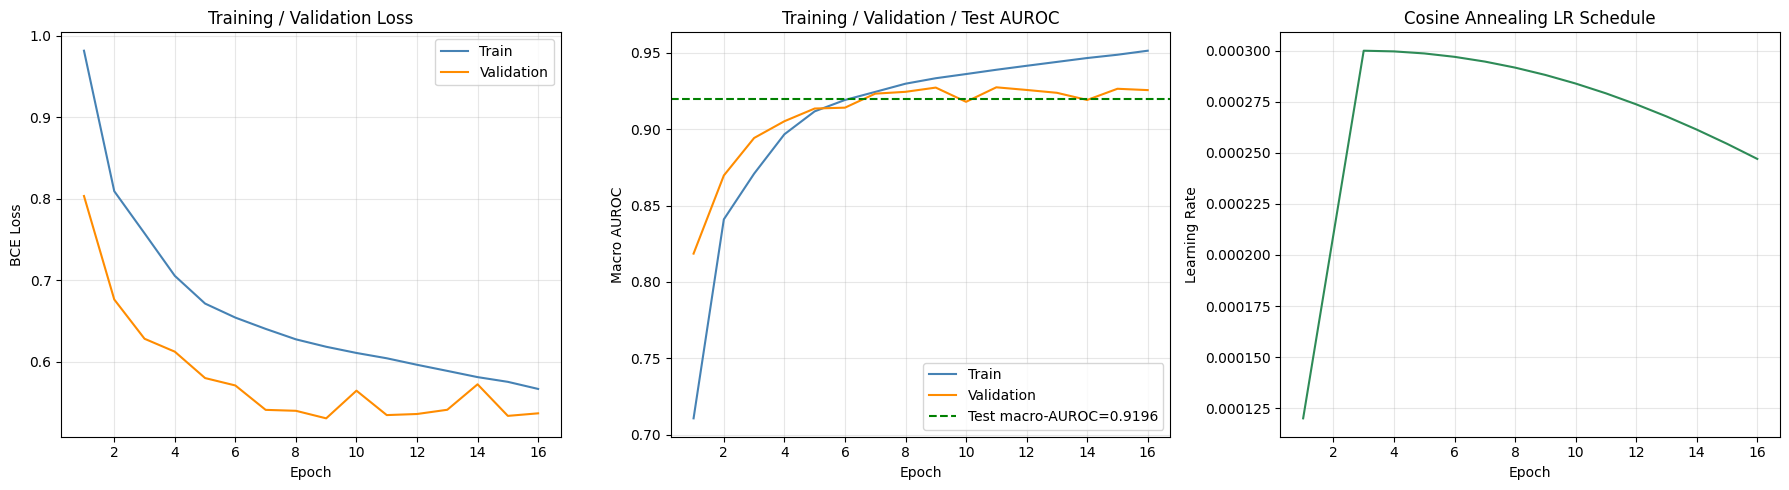

Best validation macro-AUROC : 0.9275 at epoch 11
Test macro-AUROC (this notebook, fold 10, never seen during training): 0.9196
Val -> Test macro-AUROC gap: +0.0079


In [37]:
# Section 12.2 — Training / Validation Curves
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(training_history_df["epoch"], training_history_df["train_loss"], label="Train", color="steelblue")
axes[0].plot(training_history_df["epoch"], training_history_df["val_loss"], label="Validation", color="darkorange")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss")
axes[0].set_title("Training / Validation Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(training_history_df["epoch"], training_history_df["train_auroc"], label="Train", color="steelblue")
axes[1].plot(training_history_df["epoch"], training_history_df["val_auroc"], label="Validation", color="darkorange")
axes[1].axhline(overall_metrics["macro_auroc"], color="green", linestyle="--", lw=1.5,
                label=f"Test macro-AUROC={overall_metrics['macro_auroc']:.4f}")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Macro AUROC")
axes[1].set_title("Training / Validation / Test AUROC"); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(training_history_df["epoch"], training_history_df["learning_rate"], color="seagreen")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning Rate")
axes[2].set_title("Cosine Annealing LR Schedule"); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(EVAL_CONFIG.FIGURES_DIR, "12_training_history.png"), dpi=300)
plt.show()

best_epoch = int(training_history_df.loc[training_history_df["val_auroc"].idxmax(), "epoch"])
best_val_auroc = float(training_history_df["val_auroc"].max())
print(f"Best validation macro-AUROC : {best_val_auroc:.4f} at epoch {best_epoch}")
print(f"Test macro-AUROC (this notebook, fold 10, never seen during training): "
      f"{overall_metrics['macro_auroc']:.4f}")
print(f"Val -> Test macro-AUROC gap: {best_val_auroc - overall_metrics['macro_auroc']:+.4f}")

## Section 13 — Export Results

`ExportManager` centralizes every artifact this notebook must persist for the future
supervised-vs-SSL comparison in Notebooks 07–08. Figures and tables were already saved at the
point they were generated (Sections 6–12); this section performs a final consistency sweep,
writes the one remaining text artifact (`classification_report.txt`), and prints a manifest of
everything on disk.

In [38]:
# Section 13.1 — ExportManager
# ---------------------------------------------------------------------------

class ExportManager:
    """Verifies and manifests every artifact this notebook is required to produce.

    Parameters
    ----------
    config : EVAL_CONFIG
        Supplies every output directory.
    """

    REQUIRED_FILES = {
        "predictions": ["predictions.csv"],
        "tables": ["metrics.csv", "confusion_matrix.csv", "complexity_analysis.csv"],
        "figures": ["roc_curve.png", "pr_curve.png", "confusion_matrix.png",
                    "confusion_matrix_normalized.png", "prediction_distribution.png",
                    "confidence_distribution.png", "calibration_curve.png",
                    "pca.png", "tsne.png", "umap.png"],
        "explainability": ["integrated_gradients.png", "saliency_maps.png"],
        "embeddings": ["feature_embeddings.npy"],
        "exports": ["classification_report.txt"],
    }

    def __init__(self, config):
        self.config = config
        self._dir_map = {
            "predictions": config.PREDICTIONS_DIR, "tables": config.TABLES_DIR,
            "figures": config.FIGURES_DIR, "explainability": config.EXPLAINABILITY_DIR,
            "embeddings": config.EMBEDDINGS_DIR, "exports": config.EXPORTS_DIR,
        }

    def write_classification_report(self, report_text: str) -> str:
        """Persist the sklearn classification report to `EXPORTS_DIR/classification_report.txt`."""
        path = os.path.join(self.config.EXPORTS_DIR, "classification_report.txt")
        with open(path, "w") as f:
            f.write(report_text)
        return path

    def manifest(self) -> pd.DataFrame:
        """Check every required artifact exists and return a present/missing manifest."""
        rows = []
        for category, filenames in self.REQUIRED_FILES.items():
            directory = self._dir_map[category]
            for fname in filenames:
                path = os.path.join(directory, fname)
                rows.append({
                    "category": category, "file": fname, "path": path,
                    "present": os.path.exists(path),
                    "size_kb": round(os.path.getsize(path) / 1024, 1) if os.path.exists(path) else None,
                })
        return pd.DataFrame(rows)


export_manager = ExportManager(EVAL_CONFIG)
report_path = export_manager.write_classification_report(report_text)
print(f"Saved classification report -> {report_path}")

manifest_df = export_manager.manifest()
n_missing = int((~manifest_df["present"]).sum())
print(f"\nExport manifest: {len(manifest_df) - n_missing}/{len(manifest_df)} required artifacts present.")
if n_missing:
    print("Missing artifacts:")
    print(manifest_df.loc[~manifest_df["present"], ["category", "file", "path"]].to_string(index=False))
manifest_df

Saved classification report -> ./mamba_evaluation_outputs/exports/classification_report.txt

Export manifest: 18/18 required artifacts present.


,category,file,path,present,size_kb
0,predictions,predictions.csv,./mamba_evaluation_outputs/predictions/predict...,True,190.6
1,tables,metrics.csv,./mamba_evaluation_outputs/tables/metrics.csv,True,1.3
2,tables,confusion_matrix.csv,./mamba_evaluation_outputs/tables/confusion_ma...,True,0.1
3,tables,complexity_analysis.csv,./mamba_evaluation_outputs/tables/complexity_a...,True,0.3
4,figures,roc_curve.png,./mamba_evaluation_outputs/figures/roc_curve.png,True,231.6
5,figures,pr_curve.png,./mamba_evaluation_outputs/figures/pr_curve.png,True,274.6
6,figures,confusion_matrix.png,./mamba_evaluation_outputs/figures/confusion_m...,True,150.6
7,figures,confusion_matrix_normalized.png,./mamba_evaluation_outputs/figures/confusion_m...,True,166.8
8,figures,prediction_distribution.png,./mamba_evaluation_outputs/figures/prediction_...,True,108.3
9,figures,confidence_distribution.png,./mamba_evaluation_outputs/figures/confidence_...,True,93.9


## Section 14 — Notebook Summary

The cell below regenerates the summary from the metrics actually computed in this run — no
numbers are hard-coded — so the summary always reflects the checkpoint that was evaluated.

In [39]:
# Section 14.1 — Programmatic Summary
# ---------------------------------------------------------------------------

_best_class = per_class_metrics.loc[per_class_metrics["auroc"].idxmax()]
_worst_class_row = per_class_metrics.loc[per_class_metrics["auroc"].idxmin()]
_most_fp_class = error_summary.loc[error_summary["false_positives"].idxmax(), "class"]
_most_fn_class = error_summary.loc[error_summary["false_negatives"].idxmax(), "class"]

print("=" * 78)
print("NOTEBOOK 06 — SUPERVISED MAMBA EVALUATION — SUMMARY")
print("=" * 78)

print(f"""
Checkpoint evaluated : {os.path.join(CHECKPOINT_DIR, "best_mamba.pth")}
Test fold             : official PTB-XL fold 10 ({len(results.ecg_ids)} records, never seen in training)

--- Overall performance -------------------------------------------------------
Macro AUROC            : {overall_metrics['macro_auroc']:.4f}
Micro AUROC             : {overall_metrics['micro_auroc']:.4f}
Macro F1                : {overall_metrics['macro_f1']:.4f}
Balanced accuracy (macro): {overall_metrics['balanced_accuracy_macro']:.4f}
Subset (exact-match) accuracy: {overall_metrics['subset_accuracy']:.4f}
Hamming loss            : {overall_metrics['hamming_loss']:.4f}

--- Strengths -------------------------------------------------------------------
Best-performing class by AUROC : {_best_class['class']} (AUROC={_best_class['auroc']:.4f}, F1={_best_class['f1']:.4f})
Representation space (Section 8): dominant-class clusters are visually separable in the
UMAP/t-SNE projections above, with compactness reported per class.

--- Weaknesses / failure cases ---------------------------------------------------
Weakest-performing class by AUROC : {_worst_class_row['class']} (AUROC={_worst_class_row['auroc']:.4f})
Class most prone to false positives : {_most_fp_class} ({error_summary['false_positives'].max()} FPs)
Class most prone to false negatives : {_most_fn_class} ({error_summary['false_negatives'].max()} FNs)
High-confidence errors : {len(high_conf_errors)} records misclassified with confidence >=
    {EVAL_CONFIG.HIGH_CONFIDENCE_THRESHOLD} — see Section 10.2 for representative waveforms.
Rarest-class errors : {len(rare_class_errors)} misclassifications on {rare_class}, the
    least-prevalent superclass in the test fold — the hardest case for generalization.

--- Computational profile --------------------------------------------------------
Parameters : {int(param_stats['total_parameters']):,}   |   Size on disk : {param_stats['model_size_mb']:.2f} MB
Latency (batch=1, mean) : {latency_stats['mean_latency_ms']:.2f} ms   |   Throughput : {latency_stats['throughput_samples_per_sec']:.1f} samples/sec
Estimated FLOPs (forward pass) : {flop_stats['estimated_gflops']:.3f} GFLOPs (hand-derived estimate;
    see Section 11.1 docstring for caveats)
""")

print("=" * 78)
print("All figures, tables, predictions, embeddings, and explainability artifacts have been")
print(f"exported under: {EVAL_CONFIG.OUTPUT_DIR}")
print("=" * 78)

NOTEBOOK 06 — SUPERVISED MAMBA EVALUATION — SUMMARY

Checkpoint evaluated : /kaggle/input/notebooks/shamsuzzamanhisham/ptb-xl-ecg-supervised-mamba-trainin-v2-improved/mamba_supervised_v2_outputs/checkpoints/best_mamba.pth
Test fold             : official PTB-XL fold 10 (2163 records, never seen in training)

--- Overall performance -------------------------------------------------------
Macro AUROC            : 0.9196
Micro AUROC             : 0.9267
Macro F1                : 0.7309
Balanced accuracy (macro): 0.8240
Subset (exact-match) accuracy: 0.6038
Hamming loss            : 0.1203

--- Strengths -------------------------------------------------------------------
Best-performing class by AUROC : NORM (AUROC=0.9428, F1=0.8567)
Representation space (Section 8): dominant-class clusters are visually separable in the
UMAP/t-SNE projections above, with compactness reported per class.

--- Weaknesses / failure cases ---------------------------------------------------
Weakest-performing cl

### Architecture evaluated
`MambaClassifier`: `Linear(N_LEADS -> EMBED_DIM)` input projection → `N_MAMBA_LAYERS` pre-norm
residual `MambaBlock`s (official `mamba_ssm.Mamba`) → `LayerNorm` → global average pooling over
time → `Dropout` → two-layer `ClassificationHead` → 5 multi-label logits (NORM, MI, STTC, CD,
HYP), loaded unmodified from `best_mamba.pth` and never updated in this notebook.

### What this notebook established
An unbiased, held-out (fold 10) estimate of the supervised Mamba baseline's performance, together
with its calibration, representation-space geometry, explainability profile, concrete failure
modes, and deployment cost — all persisted to disk for direct comparison against the upcoming
self-supervised variant.

### Exported artifact locations
| Category | Directory |
|---|---|
| Predictions | `EVAL_CONFIG.PREDICTIONS_DIR` |
| Metrics / confusion matrix / complexity tables | `EVAL_CONFIG.TABLES_DIR` |
| Figures (ROC, PR, confusion matrices, distributions, PCA/t-SNE/UMAP, training history) | `EVAL_CONFIG.FIGURES_DIR` |
| Explainability (Integrated Gradients, saliency, error-case waveforms) | `EVAL_CONFIG.EXPLAINABILITY_DIR` |
| Feature embeddings | `EVAL_CONFIG.EMBEDDINGS_DIR` |
| Classification report | `EVAL_CONFIG.EXPORTS_DIR` |

### Next notebook
**Notebook 07 — Hybrid Self-Supervised Mamba Pretraining** begins the self-supervised half of
this research pipeline: pretraining the same Mamba backbone with a contrastive/consistency
objective on unlabeled ECG views (via Notebook 02's `get_ssl_loader()`), before fine-tuning and
re-evaluating against the supervised baseline characterized here.